# Machine Learning for CO2 Emission Optimization in Delivery Logistics

**Dataset:** `logistics_co2_dataset.csv` (around 100,000 delivery records and 19 columns)  
**Target variable:** `co2_emission`

## About this notebook

This project looks at how machine learning can help reduce CO2 emissions in delivery logistics. We start by checking and preparing the dataset, then explore the main variables and train several regression models to predict emissions. Finally, we use the best-performing model to compare delivery configurations and identify options that could reduce emissions while meeting delivery constraints.

## Notebook outline

| Section | What we'll do |
|---|---|
| 1 | Introduce the problem and define the project objectives |
| 2 | Load the dataset and check its structure |
| 3 | Clean and prepare the data, then split it into training, validation, and test sets |
| 4 | Explore the data and visualize the main patterns |
| 5 | Select the features and check for possible data leakage |
| 6 | Train and compare regression models |
| 7 | Define the delivery optimization problem and its constraints |
| 8 | Run the optimization and compare possible delivery configurations |
| 9 | Evaluate the results against the baseline |
| 10 | Test how the results change under different constraints |
| 11 | Summarize the findings and discuss the limitations |

## 1. Introduction and problem formulation

Delivery logistics involves balancing several factors, including emissions, travel time, and the resources needed to transport goods. In this project, we explore how machine learning can help identify delivery configurations that could reduce CO2 emissions.

**Research question:** Can machine learning help find delivery configurations with lower predicted emissions without significantly increasing travel time?

### Approach

We train a regression model to predict CO2 emissions from the available delivery data. We then use its predictions to compare different configurations and look for options with lower emissions.

The optimization problem is defined as:

$$
\min_{d \in \mathcal{D}} \hat{c}(a_i, d)
$$

subject to:

$$
T(a_i, d) \leq (1+s)T_i^{\text{base}}
$$

where:

- **Delivery characteristics** are the features we keep fixed, such as distance and cargo weight.
- **Decision variables** are the choices we compare, such as vehicle type and departure time.
- **Predicted emissions** are the CO2 emissions estimated by the model.
- **Baseline travel time** is the original travel time recorded in the dataset.
- **Allowed increase** is the maximum extra travel time, set to 10% by default.

### Limitations

The dataset does not explain the vehicle and road-type codes, provide emission units, or include delivery costs. We also need to check whether the data support the comparisons we want to make.

Finally, the results depend on the quality of the dataset and the model. A reduction in predicted emissions does not necessarily mean the same reduction would occur in real deliveries.


In [105]:
import itertools
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 42
np.random.seed(SEED)

pd.set_option("display.max_columns", 40)
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.grid"] = True
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

DATA_PATH = Path("logistics_co2_dataset.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH.resolve()}"
    )

print(f"Dataset found: {DATA_PATH.resolve()}")

Dataset found: C:\Users\nours\logistics_co2_dataset.csv


## 2. Data loading and initial inspection

We load the CSV and check its size, column types, missing values, duplicates and basic statistics. 

In [108]:
raw = pd.read_csv(DATA_PATH)
print(f"Shape: {raw.shape[0]:,} rows x {raw.shape[1]} columns")
print("Columns:", list(raw.columns))
display(pd.DataFrame({"dtype": raw.dtypes.astype(str), "missing": raw.isna().sum(), "n_unique": raw.nunique()}))
print(f"\nTotal missing values: {int(raw.isna().sum().sum())}")
print(f"Duplicate rows:       {int(raw.duplicated().sum())}")

Shape: 100,000 rows x 19 columns
Columns: ['origin_lat', 'origin_lon', 'dest_lat', 'dest_lon', 'distance_km', 'avg_speed', 'traffic_index', 'elevation_gain', 'elevation_loss', 'cargo_weight', 'vehicle_type', 'road_type', 'weather_temp', 'weather_rain', 'stops_count', 'time_of_day', 'co2_emission', 'travel_time', 'delay_risk']


,dtype,missing,n_unique
origin_lat,float64,0,100000
origin_lon,float64,0,100000
dest_lat,float64,0,100000
dest_lon,float64,0,100000
distance_km,float64,0,100000
avg_speed,float64,0,100000
traffic_index,float64,0,100000
elevation_gain,float64,0,100000
elevation_loss,float64,0,100000
cargo_weight,float64,0,100000



Total missing values: 0
Duplicate rows:       0


In [109]:
print("Random sample of 8 observations:")
display(raw.sample(8, random_state=SEED))
print("\nDescriptive statistics:")
display(raw.describe().T)

# Check the statistics quoted in the assignment against the file
reported = pd.DataFrame([
    ("distance_km mean", 1007, raw["distance_km"].mean()), ("distance_km min", 10, raw["distance_km"].min()),
    ("distance_km max", 2000, raw["distance_km"].max()), ("co2_emission mean", 315.22, raw["co2_emission"].mean()),
    ("co2_emission max", 983.62, raw["co2_emission"].max()), ("cargo_weight mean", 15.49, raw["cargo_weight"].mean()),
    ("cargo_weight min", 1, raw["cargo_weight"].min()), ("cargo_weight max", 30, raw["cargo_weight"].max()),
    ("travel_time mean", 1560.87, raw["travel_time"].mean())], columns=["statistic", "reported", "computed"])
reported["abs_diff"] = (reported["reported"] - reported["computed"]).abs()
print("\nReported vs. computed statistics:")
display(reported.round(3))

Random sample of 8 observations:


,origin_lat,origin_lon,dest_lat,dest_lon,distance_km,avg_speed,traffic_index,elevation_gain,elevation_loss,cargo_weight,vehicle_type,road_type,weather_temp,weather_rain,stops_count,time_of_day,co2_emission,travel_time,delay_risk
75721,14.913167,81.842769,29.872570,76.454744,1438.348431,70.915063,0.019988,817.409798,793.924630,24.302128,2,2,16.748289,1,20,20,518.889915,1241.286273,21.399165
80184,9.832623,70.187972,25.452853,78.059129,120.689840,34.881515,0.566405,1269.864739,35.892086,5.106373,1,1,43.094618,1,24,22,28.185863,325.185218,61.648378
19864,30.430955,91.956183,11.999294,96.927111,1544.215701,46.575263,0.869647,254.773707,490.954723,1.876206,0,2,12.534417,0,49,18,303.883920,3719.319290,85.375275
76699,31.437572,77.684557,29.400873,81.961491,880.055047,53.225965,0.690063,251.482158,1172.441336,6.830940,0,2,22.398877,1,44,13,205.990293,1676.642441,80.304415
92991,16.035564,71.747184,13.567919,84.702484,482.190382,65.605495,0.465876,1123.337513,792.507381,9.325134,2,0,12.149377,0,19,9,127.846919,646.437984,42.111333
76434,16.069046,92.476010,18.509904,72.034614,711.172090,40.476960,0.796748,1335.768009,447.167280,8.129142,2,0,32.078231,0,42,0,193.984138,1894.109704,76.772329
84004,27.004903,89.218668,17.868178,88.130532,1144.875652,98.528305,0.767240,859.603391,1116.127410,29.380053,2,1,43.942988,0,34,0,525.515528,1232.094713,70.706800
80917,29.467351,88.768669,25.176488,77.737158,384.003268,76.449227,0.442974,496.487908,763.117978,10.451715,1,0,20.840044,0,44,3,99.825875,434.882050,53.008158



Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
origin_lat,100000.0,22.485159,8.361902,8.000161,15.236835,22.518264,29.735898,36.999769
origin_lon,100000.0,82.538573,8.372060,68.000139,75.270809,82.554558,89.761928,96.999692
dest_lat,100000.0,22.518103,8.375473,8.000067,15.258697,22.532930,29.762825,36.999399
dest_lon,100000.0,82.470174,8.370080,68.000065,75.220548,82.440838,89.732771,96.999844
distance_km,100000.0,1006.997921,573.654882,10.042805,509.516115,1011.269939,1501.797676,1999.996647
avg_speed,100000.0,64.966363,20.187180,30.000036,47.558507,64.866813,82.441016,99.999260
traffic_index,100000.0,0.500475,0.288541,0.000023,0.251570,0.499139,0.750698,0.999995
elevation_gain,100000.0,749.901986,432.489270,0.045764,376.389887,748.635352,1124.013367,1499.985050
elevation_loss,100000.0,753.361434,434.348621,0.001249,375.462894,757.135284,1130.251731,1499.989226
cargo_weight,100000.0,15.492953,8.362171,1.000074,8.237097,15.486111,22.713839,29.999746



Reported vs. computed statistics:


,statistic,reported,computed,abs_diff
0,distance_km mean,1007.00,1006.998,0.002
1,distance_km min,10.00,10.043,0.043
2,distance_km max,2000.00,1999.997,0.003
3,co2_emission mean,315.22,315.221,0.001
4,co2_emission max,983.62,983.619,0.001
5,cargo_weight mean,15.49,15.493,0.003
6,cargo_weight min,1.00,1.000,0.000
7,cargo_weight max,30.00,30.000,0.000
8,travel_time mean,1560.87,1560.872,0.002


**Interpretation**

The dataset contains the expected number of rows and columns, with no missing values or duplicate rows. The summary statistics also match the values reported above, allowing for rounding.

Some units are not specified in the dataset. For example, we do not know the unit used for `co2_emission` or `cargo_weight`. The values of `travel_time` could be in minutes, but this is not confirmed.

Several variables also have values spread quite evenly across specific ranges, such as speed (30-100), number of stops (0-49), and temperature (10-45). This raises the possibility that the dataset is synthetic, so we will keep this in mind when interpreting the results.

## 3. Data preprocessing

Before training the models, we prepare the data and check that the values are consistent.

1. **Missing values:** The dataset has no missing values. We still handle them in the preprocessing pipeline in case this changes later.
2. **Duplicate rows:** We check for duplicates and remove them if any are found.
3. **Data checks:** We check that variables such as speed, temperature, and rain have values within their expected ranges.
4. **Categorical variables:** `vehicle_type` and `road_type` are stored as numbers, but their codes have no known order. We therefore use one-hot encoding instead of treating them as numerical values.
5. **Outliers:** We look for unusual values using the IQR method but do not automatically remove them, since they may represent valid deliveries.
6. **Feature engineering:** We calculate the geographic distance between the origin and destination to compare it with `distance_km`. We also encode the departure hour to account for the fact that hours 23 and 0 are next to each other.
7. **Scaling:** We scale the features for the linear model. Tree-based models do not usually require this step.
8. **Train, validation, and test sets:** We split the data before fitting the preprocessing steps. Imputation, encoding, and scaling are fitted on the training data only to avoid data leakage.

In [115]:
# 3.1 Duplicates and missing values
n_before = len(raw)
df = raw.drop_duplicates().reset_index(drop=True)
print(f"Duplicates removed: {n_before - len(df)} (rows kept: {len(df):,})")
print(f"Missing values left: {int(df.isna().sum().sum())}  -> no imputation needed on this file")

# 3.2 Validity checks on bounded / binary / categorical variables
checks = {
    "vehicle_type in {0,1,2}": df["vehicle_type"].isin([0, 1, 2]).all(),
    "road_type in {0,1,2}": df["road_type"].isin([0, 1, 2]).all(),
    "weather_rain in {0,1}": df["weather_rain"].isin([0, 1]).all(),
    "traffic_index in [0,1]": df["traffic_index"].between(0, 1).all(),
    "time_of_day integer in 0..23": (df["time_of_day"].between(0, 23) & (df["time_of_day"] % 1 == 0)).all(),
    "stops_count integer >= 0": ((df["stops_count"] >= 0) & (df["stops_count"] % 1 == 0)).all(),
    "distance_km > 0": (df["distance_km"] > 0).all(),
    "cargo_weight > 0": (df["cargo_weight"] > 0).all(),
    "avg_speed > 0": (df["avg_speed"] > 0).all(),
    "co2_emission > 0": (df["co2_emission"] > 0).all(),
    "travel_time > 0": (df["travel_time"] > 0).all(),
    "delay_risk >= 0": (df["delay_risk"] >= 0).all(),
}
display(pd.Series(checks, name="passed").to_frame())
print("Category frequencies:")
for c in ["vehicle_type", "road_type", "weather_rain"]:
    print(f"  {c}:", df[c].value_counts(normalize=True).sort_index().round(3).to_dict())

Duplicates removed: 0 (rows kept: 100,000)
Missing values left: 0  -> no imputation needed on this file


,passed
"vehicle_type in {0,1,2}",True
"road_type in {0,1,2}",True
"weather_rain in {0,1}",True
"traffic_index in [0,1]",True
time_of_day integer in 0..23,True
stops_count integer >= 0,True
distance_km > 0,True
cargo_weight > 0,True
avg_speed > 0,True
co2_emission > 0,True


Category frequencies:
  vehicle_type: {0: 0.333, 1: 0.335, 2: 0.332}
  road_type: {0: 0.331, 1: 0.335, 2: 0.334}
  weather_rain: {0: 0.502, 1: 0.498}


In [14]:
# 3.3 Outlier investigation (IQR rule) - flagged, NOT removed
continuous = [c for c in df.columns if df[c].nunique() > 10]
rows = []
for c in continuous:
    q1, q3 = df[c].quantile([0.25, 0.75]); iqr = q3 - q1
    n_out = int(((df[c] < q1 - 1.5 * iqr) | (df[c] > q3 + 1.5 * iqr)).sum())
    rows.append((c, n_out, round(100 * n_out / len(df), 2), round(df[c].skew(), 2)))
display(pd.DataFrame(rows, columns=["column", "n_IQR_outliers", "pct_of_rows", "skewness"]).set_index("column"))

,n_IQR_outliers,pct_of_rows,skewness
column,,,
origin_lat,0,0.00,-0.00
origin_lon,0,0.00,-0.00
dest_lat,0,0.00,-0.00
dest_lon,0,0.00,0.01
distance_km,0,0.00,-0.01
avg_speed,0,0.00,0.01
traffic_index,0,0.00,0.00
elevation_gain,0,0.00,0.00
elevation_loss,0,0.00,-0.01


In [118]:
# 3.4 Feature engineering and consistency checks

def haversine_km(lat1, lon1, lat2, lon2):
    """Great-circle distance in km between two (lat, lon) points given in degrees."""
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371.0 * 2 * np.arcsin(np.sqrt(a))


def add_features(d):
    """Row-wise deterministic features (no statistics learned from data -> no leakage)."""
    d = d.copy()
    d["hour_sin"] = np.sin(2 * np.pi * d["time_of_day"] / 24)
    d["hour_cos"] = np.cos(2 * np.pi * d["time_of_day"] / 24)
    return d


df["gc_distance_km"] = haversine_km(df["origin_lat"], df["origin_lon"], df["dest_lat"], df["dest_lon"])
print("Great-circle distance vs distance_km:")
print(f"  Pearson r = {df['gc_distance_km'].corr(df['distance_km']):.3f}")
print(f"  distance_km / great-circle distance: median = {(df['distance_km']/df['gc_distance_km']).median():.2f}, "
      f"share of trips with route distance < great-circle distance = "
      f"{(df['distance_km'] < df['gc_distance_km']).mean():.1%}")

# Can travel_time be reconstructed from distance and speed?
base_minutes = df["distance_km"] / df["avg_speed"] * 60
ratio = df["travel_time"] / base_minutes
print("\ntravel_time / (distance/speed*60):")
print(ratio.describe().round(4).to_string())
print(f"  max |ratio - (1 + traffic_index)| = {(ratio - (1 + df['traffic_index'])).abs().max():.2e}")
df["time_identity"] = base_minutes * (1 + df["traffic_index"])
print(f"  max relative error of  travel_time = distance/speed*60*(1+traffic_index): "
      f"{((df['travel_time'] - df['time_identity']).abs() / df['travel_time']).max():.2e}")

df = add_features(df)

Great-circle distance vs distance_km:
  Pearson r = -0.004
  distance_km / great-circle distance: median = 0.63, share of trips with route distance < great-circle distance = 72.1%

travel_time / (distance/speed*60):
count    100000.0000
mean          1.5005
std           0.2885
min           1.0000
25%           1.2516
50%           1.4991
75%           1.7507
max           2.0000
  max |ratio - (1 + traffic_index)| = 1.11e-15
  max relative error of  travel_time = distance/speed*60*(1+traffic_index): 7.29e-16


**Interpretation.** Two data-supported findings matter for everything that follows:

* `distance_km` is essentially **uncorrelated with the great-circle distance** between the given coordinates (and often shorter than it, which is impossible for a real road route). The coordinates and the route distance are therefore not geographically consistent, a strong sign of **synthetic data**. The coordinates carry no usable information about distance, so they are not used as model inputs.
* `travel_time` is **exactly reproducible** as `distance / avg_speed × 60 × (1 + traffic_index)` (error at floating-point level). It is a deterministic outcome of distance, speed and traffic, not independent information. We will use this verified identity as the *delivery-time constraint* in the optimization; it is an empirical relationship found in this file, not a physical law.

Outliers (IQR rule) occur mainly in the right tails of `co2_emission` and `travel_time`; they are long or heavy trips within the observed ranges and are kept.

In [122]:
# 3.5 Train / validation / test split 
#  - train (60%): fit all models and transformers
#  - validation (20%): model selection and choice of optimization settings
#  - test (20%): held-out final evaluation (regression metrics + final optimization scenarios)
idx_trainval, idx_test = train_test_split(df.index, test_size=0.20, random_state=SEED)
idx_train, idx_val = train_test_split(idx_trainval, test_size=0.25, random_state=SEED)
train, val, test = df.loc[idx_train], df.loc[idx_val], df.loc[idx_test]
print(f"train: {len(train):,}  validation: {len(val):,}  test: {len(test):,}")
display(pd.DataFrame({"co2_mean": [train.co2_emission.mean(), val.co2_emission.mean(), test.co2_emission.mean()],
                      "distance_mean": [train.distance_km.mean(), val.distance_km.mean(), test.distance_km.mean()]},
                     index=["train", "validation", "test"]).round(2))

train: 60,000  validation: 20,000  test: 20,000


,co2_mean,distance_mean
train,315.30,1007.06
validation,315.52,1008.48
test,314.69,1005.33


## 4. Exploratory Data Analysis (EDA)


In [125]:
num_cols = [c for c in train.columns if c not in ("gc_distance_km", "time_identity", "hour_sin", "hour_cos")]
pearson = train[num_cols].corrwith(train["co2_emission"]).drop("co2_emission")
spearman = train[num_cols].corrwith(train["co2_emission"], method="spearman").drop("co2_emission")
corr_table = pd.DataFrame({"pearson": pearson, "spearman": spearman}).sort_values("pearson", key=abs, ascending=False)
print("Association of each variable with co2_emission (training split):")
display(corr_table.round(3))

print("\nCO2 by vehicle_type and road_type (training split):")
display(train.groupby("vehicle_type")["co2_emission"].agg(["count", "mean", "median", "std"]).round(2))
display(train.groupby("road_type")["co2_emission"].agg(["count", "mean", "median", "std"]).round(2))

train_eda = train.assign(co2_per_km=train["co2_emission"] / train["distance_km"])
print("\nCO2 per km by cargo-weight quartile:")
display(train_eda.groupby(pd.qcut(train_eda["cargo_weight"], 4), observed=True)["co2_per_km"].agg(["mean", "std"]).round(4))

Association of each variable with co2_emission (training split):


,pearson,spearman
distance_km,0.898,0.920
travel_time,0.718,0.814
cargo_weight,0.375,0.339
traffic_index,0.074,0.062
delay_risk,0.069,0.057
elevation_gain,0.059,0.050
origin_lat,-0.006,-0.005
avg_speed,-0.006,-0.007
dest_lat,0.005,0.005
time_of_day,0.003,0.003



CO2 by vehicle_type and road_type (training split):


,count,mean,median,std
vehicle_type,,,,
0,20037,315.55,296.68,199.24
1,20074,315.84,297.00,200.31
2,19889,314.50,294.46,200.67


,count,mean,median,std
road_type,,,,
0,19692,314.92,295.49,199.20
1,20289,315.04,296.05,200.73
2,20019,315.94,296.97,200.27



CO2 per km by cargo-weight quartile:


,mean,std
cargo_weight,,
"(0.999, 8.221]",0.2171,0.0226
"(8.221, 15.508]",0.2810,0.0255
"(15.508, 22.725]",0.3448,0.0282
"(22.725, 29.998]",0.4086,0.0312


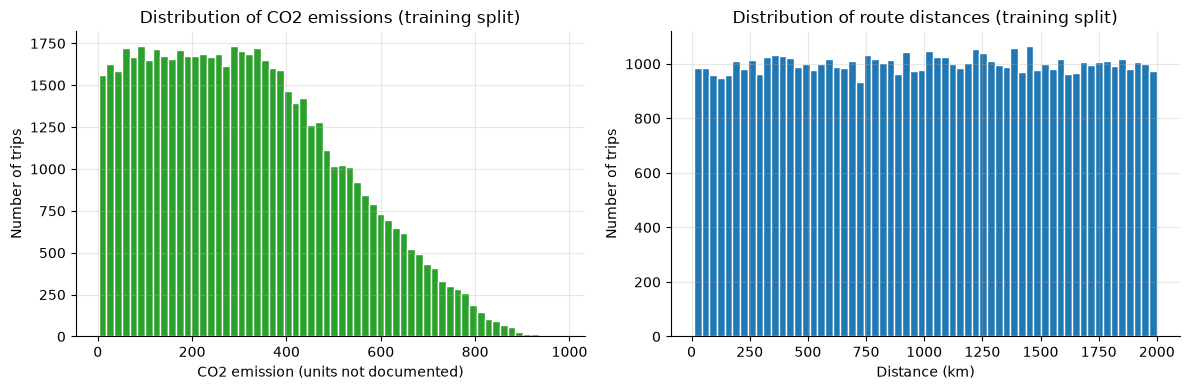

CO2 skewness = 0.46;  distance skewness = -0.00


In [127]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(train["co2_emission"], bins=60, color="tab:green", edgecolor="white")
ax[0].set(title="Distribution of CO2 emissions (training split)", xlabel="CO2 emission (units not documented)", ylabel="Number of trips")
ax[1].hist(train["distance_km"], bins=60, color="tab:blue", edgecolor="white")
ax[1].set(title="Distribution of route distances (training split)", xlabel="Distance (km)", ylabel="Number of trips")
plt.tight_layout(); plt.show()
print(f"CO2 skewness = {train['co2_emission'].skew():.2f};  distance skewness = {train['distance_km'].skew():.2f}")

**Interpretation.** Route distances are spread almost uniformly between about 10 and 2,000 km (skewness near zero), which is unusual for real delivery data and consistent with synthetic generation. CO2 emissions are right-skewed with a long tail of high-emission trips; this skew is inherited from the combination of distance and cargo (shown next) rather than from isolated anomalies.

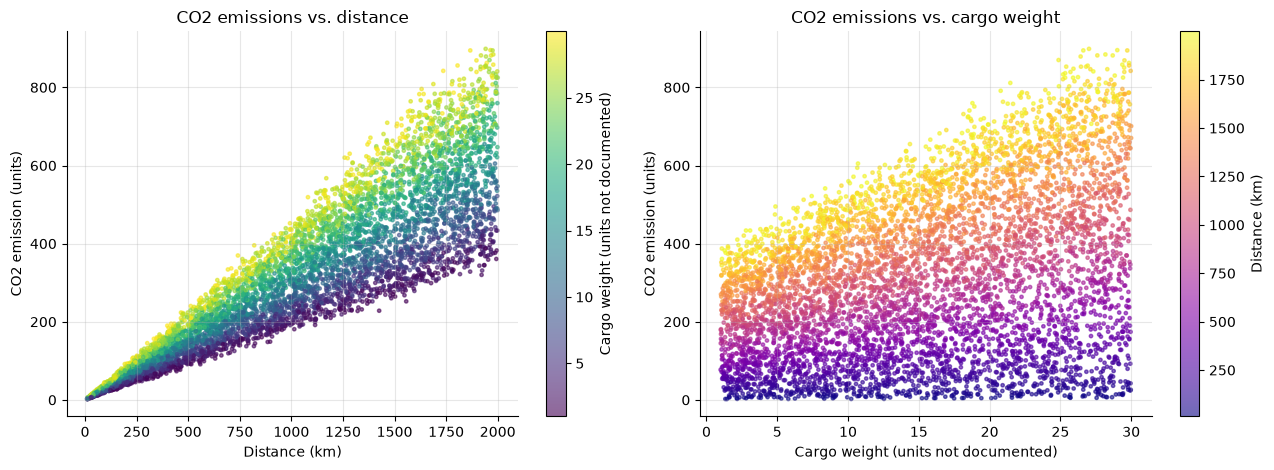

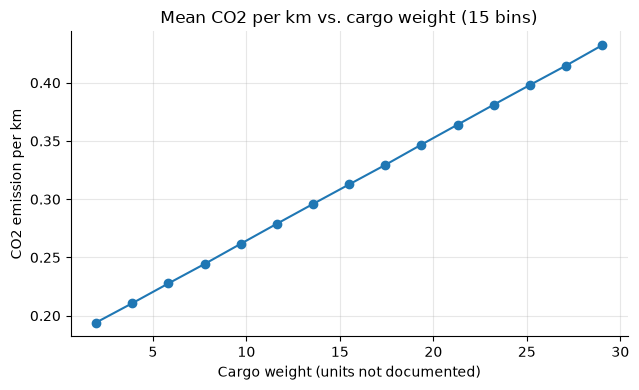

In [130]:
samp = train.sample(6000, random_state=SEED)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
sc = ax[0].scatter(samp["distance_km"], samp["co2_emission"], c=samp["cargo_weight"], s=6, cmap="viridis", alpha=0.6)
plt.colorbar(sc, ax=ax[0], label="Cargo weight (units not documented)")
ax[0].set(title="CO2 emissions vs. distance", xlabel="Distance (km)", ylabel="CO2 emission (units)")

sc2 = ax[1].scatter(samp["cargo_weight"], samp["co2_emission"], c=samp["distance_km"], s=6, cmap="plasma", alpha=0.6)
plt.colorbar(sc2, ax=ax[1], label="Distance (km)")
ax[1].set(title="CO2 emissions vs. cargo weight", xlabel="Cargo weight (units not documented)", ylabel="CO2 emission (units)")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(6.5, 4))
b = train_eda.groupby(pd.cut(train_eda["cargo_weight"], 15), observed=True)["co2_per_km"].mean()
ax.plot([iv.mid for iv in b.index], b.values, marker="o")
ax.set(title="Mean CO2 per km vs. cargo weight (15 bins)", xlabel="Cargo weight (units not documented)", ylabel="CO2 emission per km")
plt.tight_layout(); plt.show()

**Interpretation.** Emissions grow with distance, and at a given distance heavier cargo produces higher emissions (colour gradient). The per-km view isolates the cargo effect: emissions per kilometre increase steadily and almost linearly with cargo weight. The strong distance and cargo relationships already explain most of the variance (see correlation table above); once distance and cargo are both taken into account (colour), the remaining scatter is small, which is atypical for real-world emission data.

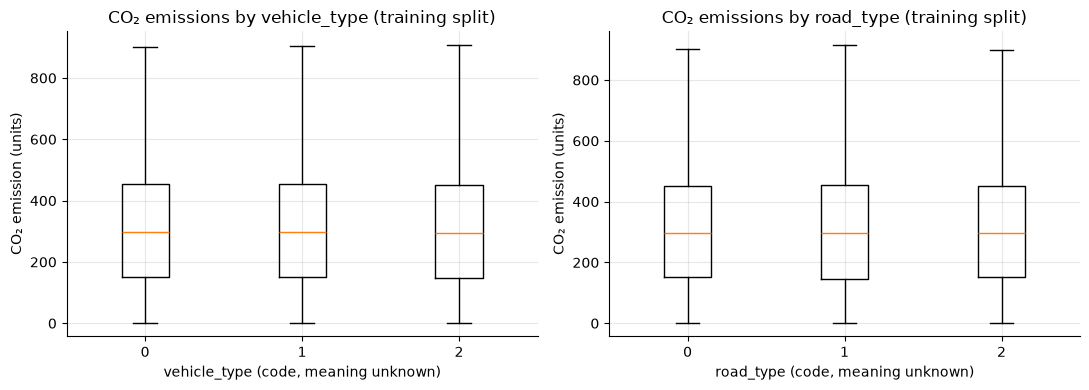

In [30]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, col in zip(ax, ["vehicle_type", "road_type"]):
    levels = sorted(train[col].unique())
    a.boxplot([train.loc[train[col] == l, "co2_emission"] for l in levels], showfliers=False)
    a.set_xticks(range(1, len(levels) + 1)); a.set_xticklabels(levels)
    a.set(title=f"CO2 emissions by {col} (training split)", xlabel=f"{col} (code, meaning unknown)", ylabel="CO2 emission (units)")
plt.tight_layout(); plt.show()

**Interpretation.** The distributions for the three vehicle codes, and for the three road codes, are practically identical (similar medians and spreads; compare with the group means printed above). Taken at face value, *neither categorical variable changes emissions*. Whether this is a real property of the data or only a marginal effect hidden by distance and cargo is tested formally in Sections 6 and 7, because it decides which decisions an optimizer could use.

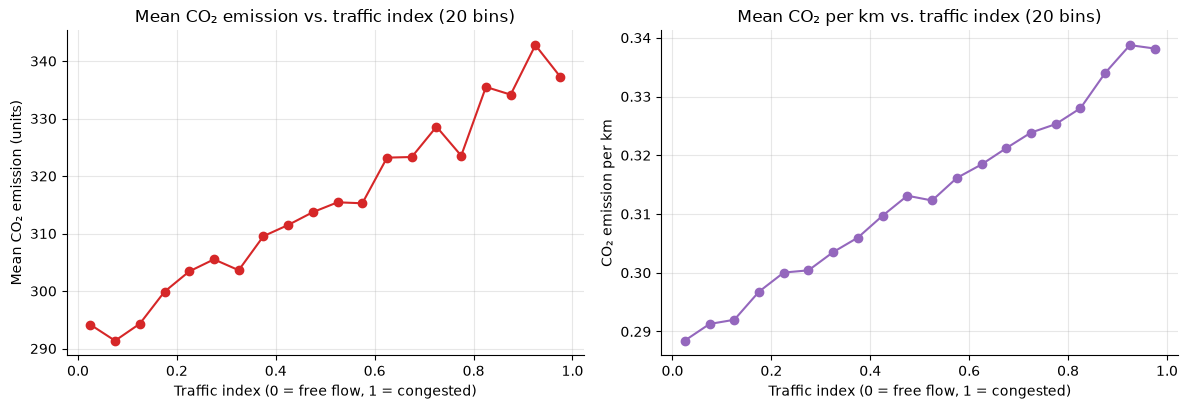

Mean CO2/km in the lowest vs highest traffic bin: 0.2884 vs 0.3382


In [33]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
tb = train_eda.groupby(pd.cut(train_eda["traffic_index"], 20), observed=True)[["co2_emission", "co2_per_km"]].mean()
mid = [iv.mid for iv in tb.index]
ax[0].plot(mid, tb["co2_emission"], marker="o", color="tab:red")
ax[0].set(title="Mean CO2 emission vs. traffic index (20 bins)", xlabel="Traffic index (0 = free flow, 1 = congested)", ylabel="Mean CO2 emission (units)")
ax[1].plot(mid, tb["co2_per_km"], marker="o", color="tab:purple")
ax[1].set(title="Mean CO2 per km vs. traffic index (20 bins)", xlabel="Traffic index (0 = free flow, 1 = congested)", ylabel="CO2 emission per km")
plt.tight_layout(); plt.show()
print(f"Mean CO2/km in the lowest vs highest traffic bin: {tb['co2_per_km'].iloc[0]:.4f} vs {tb['co2_per_km'].iloc[-1]:.4f}")

**Interpretation.** Emissions per kilometre rise with congestion, so traffic has a real, monotonic effect on emissions. Its raw correlation with total emissions is weak because the large variation of trip distance dominates the totals; the per-km view reveals it.

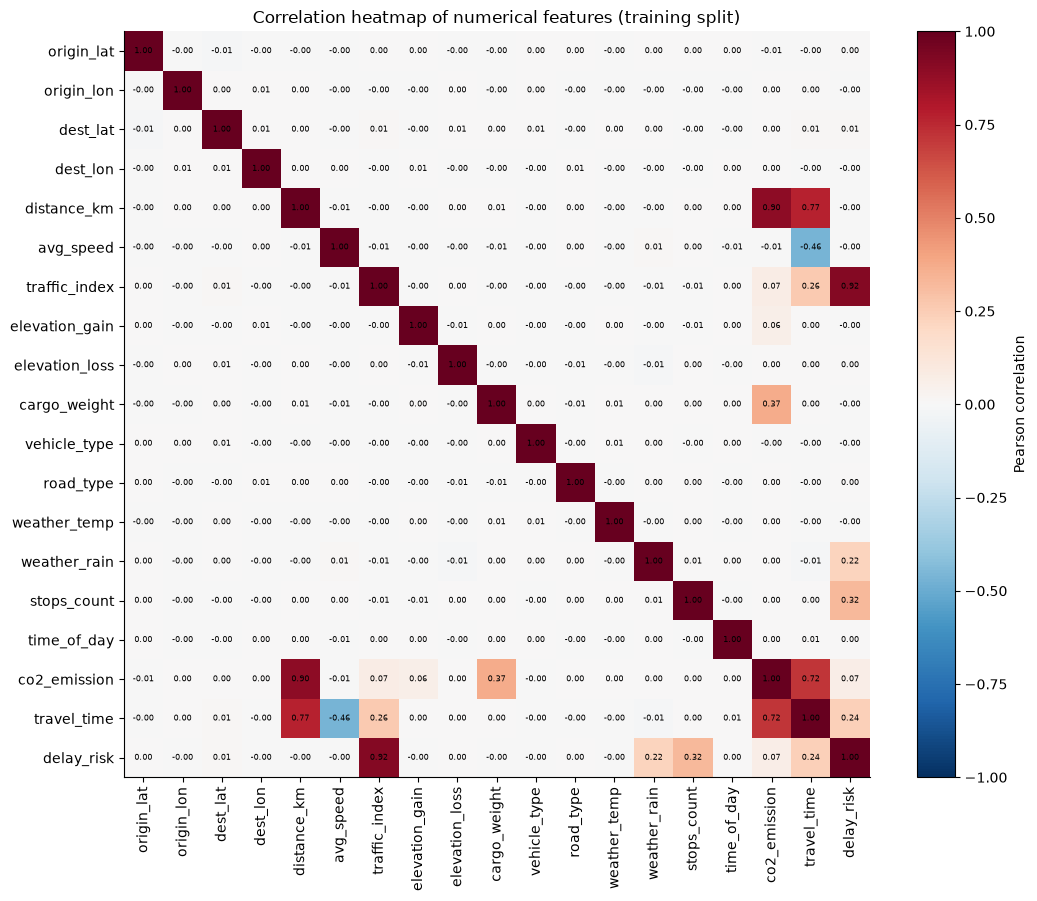

In [36]:
heat_cols = [c for c in num_cols]
cm = train[heat_cols].corr()
fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(cm.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(heat_cols))); ax.set_xticklabels(heat_cols, rotation=90)
ax.set_yticks(range(len(heat_cols))); ax.set_yticklabels(heat_cols)
for i in range(len(heat_cols)):
    for j in range(len(heat_cols)):
        ax.text(j, i, f"{cm.values[i, j]:.2f}", ha="center", va="center", fontsize=6)
ax.grid(False)
plt.colorbar(im, ax=ax, label="Pearson correlation")
ax.set_title("Correlation heatmap of numerical features (training split)")
plt.tight_layout(); plt.show()

**Interpretation.** Apart from the links involving the derived columns (`travel_time`, `delay_risk`) and the target, almost all off-diagonal cells are near zero: the input variables are essentially **independent of each other** (for example, traffic is unrelated to the hour of day, and speed is unrelated to traffic). Real operations normally show such links (rush hours, speed falling with congestion). `delay_risk` is the notable exception: it is strongly tied to traffic. Independence of the inputs is typical of data in which every column was drawn separately; this has consequences for the optimization (Section 7).

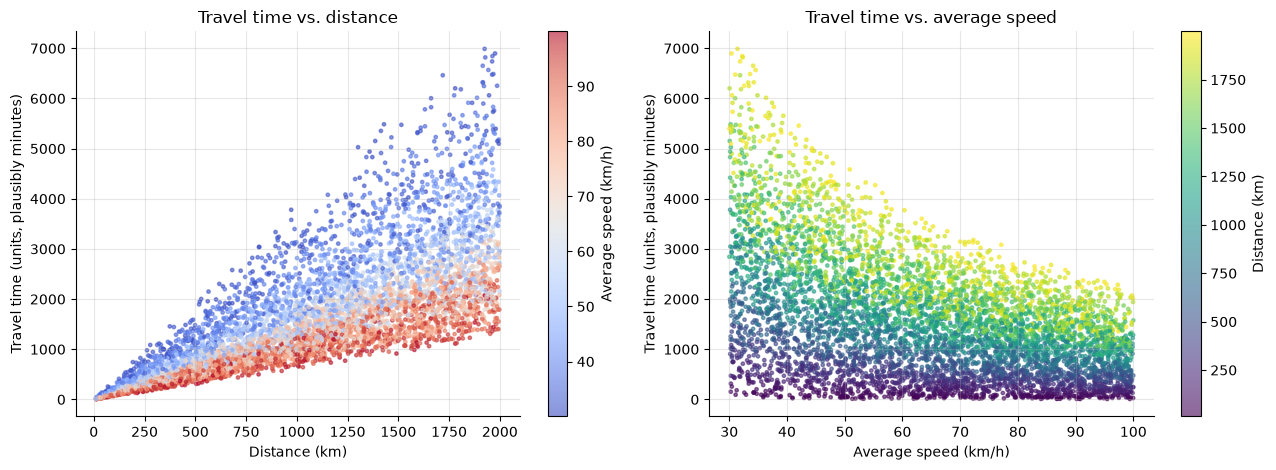

In [39]:
samp = train.sample(6000, random_state=SEED)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
sc = ax[0].scatter(samp["distance_km"], samp["travel_time"], c=samp["avg_speed"], s=6, cmap="coolwarm", alpha=0.6)
plt.colorbar(sc, ax=ax[0], label="Average speed (km/h)")
ax[0].set(title="Travel time vs. distance", xlabel="Distance (km)", ylabel="Travel time (units, plausibly minutes)")
sc2 = ax[1].scatter(samp["avg_speed"], samp["travel_time"], c=samp["distance_km"], s=6, cmap="viridis", alpha=0.6)
plt.colorbar(sc2, ax=ax[1], label="Distance (km)")
ax[1].set(title="Travel time vs. average speed", xlabel="Average speed (km/h)", ylabel="Travel time (units, plausibly minutes)")
plt.tight_layout(); plt.show()

**Interpretation.** Travel time increases with distance and decreases hyperbolically with speed : the signature of *time = distance / speed*, with an extra traffic multiplier (Section 3.4 verified the exact formula). Speed therefore acts on travel time, but we have seen no sign that it acts on emissions; this is checked formally next.

## 5. Feature selection and leakage analysis

The target is `co2_emission`. A model is only useful for dispatch decisions if it uses information that is known **before departure**. Each column is classified below, with evidence from the training split.

In [43]:
corr_co2 = train[num_cols].corrwith(train["co2_emission"])

# delay_risk: how much of it is explained by other columns (is it a derived outcome?)
dr_cols = ["distance_km", "avg_speed", "traffic_index", "elevation_gain", "cargo_weight", "stops_count",
           "weather_rain", "weather_temp", "vehicle_type", "road_type", "time_of_day"]
dr_model = HistGradientBoostingRegressor(random_state=SEED).fit(train[dr_cols], train["delay_risk"])
dr_r2 = r2_score(val["delay_risk"], dr_model.predict(val[dr_cols]))
print(f"delay_risk is predictable from other columns: validation R2 = {dr_r2:.3f}; corr(delay_risk, traffic_index) = "
      f"{train['delay_risk'].corr(train['traffic_index']):.3f}; corr(delay_risk, co2) = {corr_co2['delay_risk']:.3f}")

roles = [
    ("distance_km", "Route attribute", "Pre-dispatch", "Known once the delivery is planned."),
    ("cargo_weight", "Delivery attribute", "Pre-dispatch", "Known from the order."),
    ("traffic_index", "Forecast", "Pre-dispatch (as a forecast)", "Assumed to be a forecast available at dispatch; its realised value would be an outcome."),
    ("elevation_gain", "Route attribute", "Pre-dispatch", "Known from the route profile."),
    ("elevation_loss", "Route attribute", "Pre-dispatch", "Known from the route profile."),
    ("stops_count", "Delivery attribute", "Pre-dispatch", "Planned number of stops."),
    ("weather_temp", "Forecast", "Pre-dispatch (as a forecast)", "Assumed forecast."),
    ("weather_rain", "Forecast", "Pre-dispatch (as a forecast)", "Assumed forecast."),
    ("vehicle_type", "Decision", "Pre-dispatch", "Chosen at dispatch (meaning of codes unknown)."),
    ("road_type", "Decision", "Pre-dispatch", "Chosen at dispatch (meaning of codes unknown)."),
    ("time_of_day", "Decision", "Pre-dispatch", "Departure hour."),
    ("avg_speed", "Trip outcome", "Excluded (post-trip)", "Observed average speed; only a planned speed is known before departure."),
    ("travel_time", "Trip outcome", "Excluded (post-trip)", "Exact function of distance, speed and traffic (Section 3.4) -> redundant and unknown before the trip."),
    ("delay_risk", "Trip outcome", "Excluded (post-trip)", "Derived score: almost fully predictable from other columns (R² printed above) and tied to traffic; not a dispatch-time input."),
    ("origin_lat / origin_lon / dest_lat / dest_lon", "Coordinates", "Excluded", "Not consistent with distance_km (Section 3.4) and uncorrelated with the target."),
]
leak = pd.DataFrame(roles, columns=["feature", "role", "setting", "reason"])
leak["corr_with_co2"] = [corr_co2.get(f, np.nan) if "/" not in f else
                         corr_co2[["origin_lat", "origin_lon", "dest_lat", "dest_lon"]].abs().max()
                         for f in leak["feature"]]
pd.set_option("display.max_colwidth", 110)
display(leak.round(3))

CAT_FEATURES = ["vehicle_type", "road_type"]
PRE_FEATURES = ["distance_km", "cargo_weight", "traffic_index", "elevation_gain", "elevation_loss", "stops_count",
                "weather_temp", "weather_rain", "hour_sin", "hour_cos", "vehicle_type", "road_type"]
POST_FEATURES = PRE_FEATURES + ["avg_speed", "travel_time", "delay_risk"]
print("\nPre-dispatch features :", PRE_FEATURES)
print("Post-trip additions   :", [f for f in POST_FEATURES if f not in PRE_FEATURES])

C:\Users\nours\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\nours\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\nours\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\nours\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\nours\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreatePro

delay_risk is predictable from other columns: validation R2 = 1.000; corr(delay_risk, traffic_index) = 0.916; corr(delay_risk, co2) = 0.069


,feature,role,setting,reason,corr_with_co2
0,distance_km,Route attribute,Pre-dispatch,Known once the delivery is planned.,0.898
1,cargo_weight,Delivery attribute,Pre-dispatch,Known from the order.,0.375
2,traffic_index,Forecast,Pre-dispatch (as a forecast),Assumed to be a forecast available at dispatch; its realised value would be an outcome.,0.074
3,elevation_gain,Route attribute,Pre-dispatch,Known from the route profile.,0.059
4,elevation_loss,Route attribute,Pre-dispatch,Known from the route profile.,0.000
5,stops_count,Delivery attribute,Pre-dispatch,Planned number of stops.,0.002
6,weather_temp,Forecast,Pre-dispatch (as a forecast),Assumed forecast.,0.001
7,weather_rain,Forecast,Pre-dispatch (as a forecast),Assumed forecast.,0.001
8,vehicle_type,Decision,Pre-dispatch,Chosen at dispatch (meaning of codes unknown).,-0.002
9,road_type,Decision,Pre-dispatch,Chosen at dispatch (meaning of codes unknown).,0.002



Pre-dispatch features : ['distance_km', 'cargo_weight', 'traffic_index', 'elevation_gain', 'elevation_loss', 'stops_count', 'weather_temp', 'weather_rain', 'hour_sin', 'hour_cos', 'vehicle_type', 'road_type']
Post-trip additions   : ['avg_speed', 'travel_time', 'delay_risk']


**Two prediction settings.**

1. **Pre-dispatch prediction** (`PRE_FEATURES`): only information plausibly known before departure. **This setting is used for the optimization**, because the optimizer must evaluate decisions that have not happened yet.
2. **Operational / post-trip estimation** (`POST_FEATURES`): adds the observed speed, travel time and delay risk. Section 6 compares both settings to see whether the post-trip outcomes add anything; they must not be used to evaluate dispatch decisions.

*Limitation:* `traffic_index` and the weather variables are treated as forecasts available at dispatch. In the data they are single values per trip; whether they were forecast or measured is not documented.

## 6. Machine-learning models

Four regression models are trained on the **training split** with the same pre-dispatch features and the same preprocessing logic inside scikit-learn pipelines (imputation -> [scaling for Ridge] -> one-hot encoding of the categorical codes):

* `DummyRegressor` (predicts the training mean) - the baseline any model must beat;
* `Ridge` regression on the raw features - a linear, interpretable model;
* `Ridge` regression **with interaction terms** - the same linear learner, with inputs motivated by the EDA of Section 4 (emissions per km grow linearly with cargo and rise with traffic, so distance × cargo, distance × traffic, … are natural terms). The interaction features are row-wise products of inputs (no statistics learned from data), so they cannot leak;
* `RandomForestRegressor` - a bagged tree ensemble;
* `HistGradientBoostingRegressor` - a gradient-boosting model.

Models are compared on the **validation split**; the best one is chosen from validation RMSE, and **test-split** metrics are reported afterwards as an untouched final check.

In [47]:
# Interaction features motivated by the EDA (pure row-wise functions of the inputs -> no leakage)
def add_interactions(d):
    d = d.copy()
    d["d_x_c"] = d["distance_km"] * d["cargo_weight"]
    d["d_x_t"] = d["distance_km"] * d["traffic_index"]
    d["d_x_c_x_t"] = d["d_x_c"] * d["traffic_index"]
    d["d_x_e"] = d["distance_km"] * d["elevation_gain"]
    d["d_x_c_x_e"] = d["d_x_c"] * d["elevation_gain"]
    return d


def prepare(d):
    """All engineered pre-dispatch inputs (hour encoding + interactions)."""
    return add_interactions(add_features(d))


INTERACTIONS = ["d_x_c", "d_x_t", "d_x_c_x_t", "d_x_e", "d_x_c_x_e"]
PRE_ENG = PRE_FEATURES + INTERACTIONS          # superset of pre-dispatch inputs; each model uses its own subset
train, val, test = (add_interactions(x) for x in (train, val, test))


def make_pipeline(estimator, features, scale=False):
    """Preprocessing + model in one object, so that all transformers are fitted on training data only.
    The ColumnTransformer selects its own columns by name, so every model can be fed the superset PRE_ENG."""
    cat = [c for c in features if c in CAT_FEATURES]
    num = [c for c in features if c not in CAT_FEATURES]
    num_steps = [("impute", SimpleImputer(strategy="median"))] + ([("scale", StandardScaler())] if scale else [])
    prep = ColumnTransformer([
        ("num", Pipeline(num_steps), num),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat)])
    return Pipeline([("prep", prep), ("model", estimator)])


def evaluate(model, X, y):
    pred = model.predict(X)
    return {"MAE": mean_absolute_error(y, pred), "RMSE": float(np.sqrt(mean_squared_error(y, pred))), "R2": r2_score(y, pred)}


TARGET = "co2_emission"
# name: (estimator, input features, scale numeric inputs?)
model_specs = {
    "Dummy (train mean)": (DummyRegressor(strategy="mean"), PRE_FEATURES, False),
    "Ridge (raw features)": (Ridge(alpha=1.0), PRE_FEATURES, True),
    "Ridge + interactions": (Ridge(alpha=1e-3), PRE_ENG, True),
    "Random Forest": (RandomForestRegressor(n_estimators=100, min_samples_leaf=5, n_jobs=-1, random_state=SEED), PRE_FEATURES, False),
    "HistGradientBoosting": (HistGradientBoostingRegressor(max_iter=300, learning_rate=0.1, random_state=SEED), PRE_FEATURES, False),
}

fitted, model_feats, rows = {}, {}, []
for name, (est, feats, scale) in model_specs.items():
    t0 = time.time()
    pipe = make_pipeline(est, feats, scale=scale).fit(train[feats], train[TARGET])
    fit_s = time.time() - t0
    fitted[name], model_feats[name] = pipe, feats
    v, t = evaluate(pipe, val[feats], val[TARGET]), evaluate(pipe, test[feats], test[TARGET])
    rows.append({"model": name, "val_MAE": v["MAE"], "val_RMSE": v["RMSE"], "val_R2": v["R2"],
                 "test_MAE": t["MAE"], "test_RMSE": t["RMSE"], "test_R2": t["R2"], "fit_seconds": fit_s})
results = pd.DataFrame(rows).set_index("model").sort_values("val_RMSE")
display(results.apply(lambda col: col.map(lambda v: f"{v:.4g}")))

best_name = results.index[0]
best_model = fitted[best_name]
best_feats = model_feats[best_name]
# audit model for Section 8: best remaining non-dummy model (a different learner than the one used by the optimizer)
audit_name = [m for m in results.index if m not in (best_name, "Dummy (train mean)")][0]
audit_model = fitted[audit_name]
print(f"\nSelected model (lowest validation RMSE): {best_name};  audit model for Section 8: {audit_name}")

,val_MAE,val_RMSE,val_R2,test_MAE,test_RMSE,test_R2,fit_seconds
model,,,,,,,
Ridge + interactions,2.88e-06,4.205e-06,1,2.917e-06,4.256e-06,1,0.264
HistGradientBoosting,2.397,3.204,0.9997,2.411,3.223,0.9997,5.459
Random Forest,4.067,5.846,0.9992,4.094,5.865,0.9991,12.85
Ridge (raw features),32.66,44.18,0.9518,32.53,43.91,0.9523,2.497
Dummy (train mean),166.9,201.2,-1.144e-06,167.2,201.1,-9.397e-06,0.3207



Selected model (lowest validation RMSE): Ridge + interactions;  audit model for Section 8: HistGradientBoosting


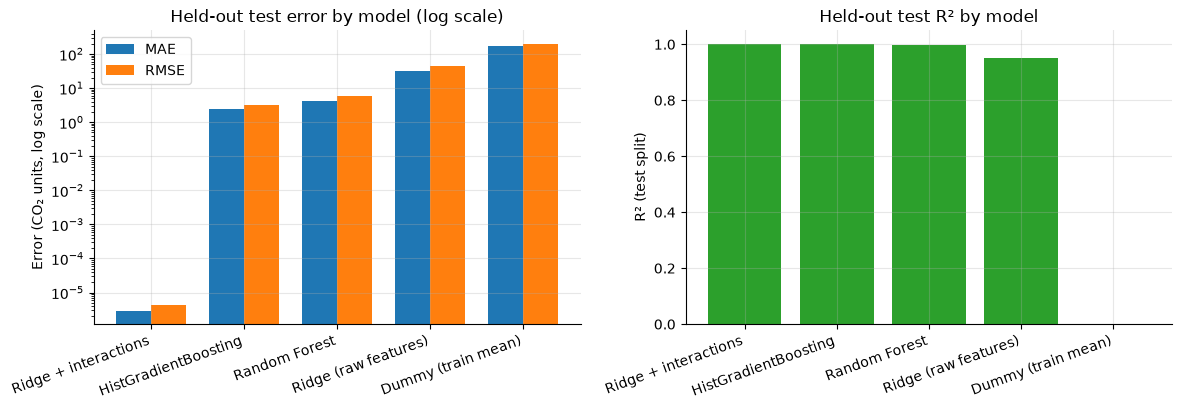

In [49]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
order = results.index.tolist()
x = np.arange(len(order)); w = 0.38
ax[0].bar(x - w / 2, results["test_MAE"], w, label="MAE"); ax[0].bar(x + w / 2, results["test_RMSE"], w, label="RMSE")
ax[0].set_yscale("log"); ax[0].set_xticks(x); ax[0].set_xticklabels(order, rotation=20, ha="right")
ax[0].set(title="Held-out test error by model (log scale)", ylabel="Error (CO2 units, log scale)"); ax[0].legend()
ax[1].bar(order, results["test_R2"], color="tab:green")
ax[1].set_xticks(range(len(order))); ax[1].set_xticklabels(order, rotation=20, ha="right")
ax[1].set(title="Held-out test R² by model", ylabel="R² (test split)")
plt.tight_layout(); plt.show()

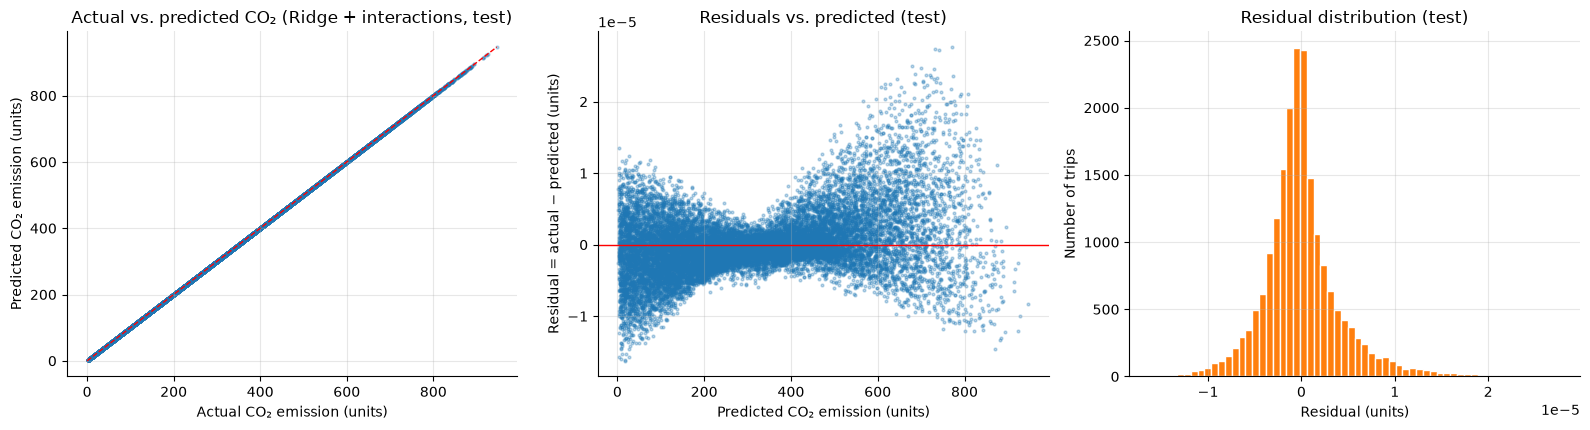

Residuals of Ridge + interactions: mean = 1.59e-08, std = 4.26e-06, 1st/99th percentile = -9.8e-06 / 1.44e-05
Median absolute percentage error: 6.73e-09
Random Forest: residual std = 5.86 units;  median absolute percentage error = 0.012
HistGradientBoosting: residual std = 3.22 units;  median absolute percentage error = 0.00754


In [50]:
# Diagnostics of the selected model on the TEST split
pred_test = best_model.predict(test[best_feats])
resid = test[TARGET] - pred_test
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
ax[0].scatter(test[TARGET], pred_test, s=4, alpha=0.3)
lim = [0, test[TARGET].max()]
ax[0].plot(lim, lim, "r--", lw=1); ax[0].set(title=f"Actual vs. predicted CO2 ({best_name}, test)", xlabel="Actual CO2 emission (units)", ylabel="Predicted CO2 emission (units)")
ax[1].scatter(pred_test, resid, s=4, alpha=0.3); ax[1].axhline(0, color="r", lw=1)
ax[1].set(title="Residuals vs. predicted (test)", xlabel="Predicted CO2 emission (units)", ylabel="Residual = actual − predicted (units)")
ax[2].hist(resid, bins=60, color="tab:orange", edgecolor="white")
ax[2].set(title="Residual distribution (test)", xlabel="Residual (units)", ylabel="Number of trips")
plt.tight_layout(); plt.show()
print(f"Residuals of {best_name}: mean = {resid.mean():.3g}, std = {resid.std():.3g}, 1st/99th percentile = "
      f"{resid.quantile(0.01):.3g} / {resid.quantile(0.99):.3g}")
print(f"Median absolute percentage error: {(resid.abs() / test[TARGET]).median():.3g}")
# For comparison: the tree-based models make much larger errors, especially for small trips
for nm in ["Random Forest", "HistGradientBoosting"]:
    r_ = test[TARGET] - fitted[nm].predict(test[model_feats[nm]])
    print(f"{nm}: residual std = {r_.std():.3g} units;  median absolute percentage error = {(r_.abs() / test[TARGET]).median():.3g}")

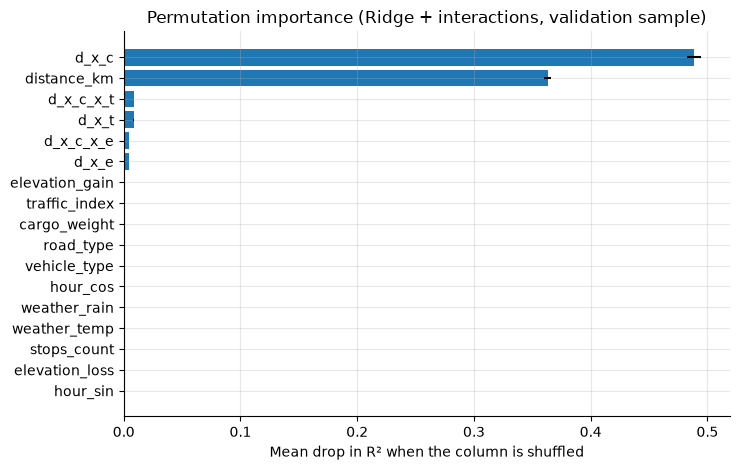

(interaction columns are shuffled as separate columns, which breaks their link with the raw inputs)


,importance,std
d_x_c,0.4884,0.0062
distance_km,0.3632,0.0032
d_x_c_x_t,0.0085,0.0001
d_x_t,0.0084,0.0002
d_x_c_x_e,0.0049,0.0000
d_x_e,0.0048,0.0000
elevation_gain,0.0000,0.0000
traffic_index,0.0000,0.0000
cargo_weight,0.0000,0.0000
elevation_loss,0.0000,0.0000


In [53]:
# Permutation importance on the validation split (drop in R2 when a column is shuffled)
vs = val.sample(5000, random_state=SEED)
imp = permutation_importance(best_model, vs[best_feats], vs[TARGET], n_repeats=3, random_state=SEED, n_jobs=1)
imp_df = pd.DataFrame({"importance": imp.importances_mean, "std": imp.importances_std}, index=best_feats).sort_values("importance")
fig, ax = plt.subplots(figsize=(7.5, 4.8))
ax.barh(imp_df.index, imp_df["importance"], xerr=imp_df["std"], color="tab:blue")
ax.set(title=f"Permutation importance ({best_name}, validation sample)", xlabel="Mean drop in R² when the column is shuffled")
plt.tight_layout(); plt.show()
print("(interaction columns are shuffled as separate columns, which breaks their link with the raw inputs)")
display(imp_df.sort_values("importance", ascending=False).round(4))

In [55]:
# Operational / post-trip setting: do observed speed, travel time and delay risk add anything?
post = make_pipeline(HistGradientBoostingRegressor(max_iter=300, random_state=SEED), POST_FEATURES).fit(train[POST_FEATURES], train[TARGET])
pre_h = fitted["HistGradientBoosting"]
cmp_df = pd.DataFrame({
    "pre-dispatch (HistGB)": evaluate(pre_h, test[PRE_FEATURES], test[TARGET]),
    "post-trip (HistGB)": evaluate(post, test[POST_FEATURES], test[TARGET])}).T
print("Test metrics of the two prediction settings (same learner):"); display(cmp_df.round(3))

# Is the target an exact closed-form function? Plain least squares on the interaction terms (train -> test)
terms = ["distance_km"] + INTERACTIONS
probe = LinearRegression().fit(train[terms], train[TARGET])
coef = pd.Series(probe.coef_, index=terms)
err = (test[TARGET] - probe.predict(test[terms])).abs()
print("\nLeast-squares fit of co2_emission on distance and its interactions (training split):")
display(coef.to_frame("coefficient"))
print(f"intercept = {probe.intercept_:.3g};  TEST max |error| = {err.max():.2e}, mean |error| = {err.mean():.2e}, "
      f"R2 = {r2_score(test[TARGET], probe.predict(test[terms])):.12f}")
print("Does the traffic / elevation multiplier factor out of the cargo term?  (equal ratios would mean co2 = distance x f(cargo) x g(traffic, elevation))")
print(f"  coef(d_x_t)/coef(distance_km)   = {coef['d_x_t'] / coef['distance_km']:.6g}   vs   coef(d_x_c_x_t)/coef(d_x_c) = {coef['d_x_c_x_t'] / coef['d_x_c']:.6g}")
print(f"  coef(d_x_e)/coef(distance_km)   = {coef['d_x_e'] / coef['distance_km']:.6g}   vs   coef(d_x_c_x_e)/coef(d_x_c) = {coef['d_x_c_x_e'] / coef['d_x_c']:.6g}")

Test metrics of the two prediction settings (same learner):


,MAE,RMSE,R2
pre-dispatch (HistGB),2.411,3.223,1.0
post-trip (HistGB),2.528,3.369,1.0



Least-squares fit of co2_emission on distance and its interactions (training split):


,coefficient
distance_km,1.500000e-01
d_x_c,7.500000e-03
d_x_t,3.000000e-02
d_x_c_x_t,1.500000e-03
d_x_e,1.500000e-05
d_x_c_x_e,7.500000e-07


intercept = -3.58e-12;  TEST max |error| = 5.98e-11, mean |error| = 1.27e-11, R2 = 1.000000000000
Does the traffic / elevation multiplier factor out of the cargo term?  (equal ratios would mean co2 = distance x f(cargo) x g(traffic, elevation))
  coef(d_x_t)/coef(distance_km)   = 0.2   vs   coef(d_x_c_x_t)/coef(d_x_c) = 0.2
  coef(d_x_e)/coef(distance_km)   = 0.0001   vs   coef(d_x_c_x_e)/coef(d_x_c) = 0.0001


**Interpretation and caution.**

* All learned models beat the mean baseline by a very large margin. The linear model with interaction terms is the most accurate on the validation split by a wide margin : its errors are of the order of millionths of a unit, far below those of the random forest and the gradient-boosting model (see the table; the log-scale figure makes the gap visible). The tree ensembles reach a high R² too, but their errors in *absolute* units are several orders of magnitude larger (a few units per trip, see the residual statistics printed above): **a high R² alone does not mean a precise model.**
* The least-squares probe shows why. `co2_emission` is reproduced with errors at floating-point level by distance, distance × cargo, and their products with traffic and elevation gain, and the traffic / elevation multipliers are *identical* for the cargo-free and the cargo-dependent term (the printed ratios agree). So, in this file, emissions behave as **distance × (a + b · cargo) × (1 + c · traffic + e · elevation gain)** with no noise. This is a **hypothesis strongly supported by the data** about how the file was generated; it is certainly not how real fleets emit, and a model that has learned it should not be expected to generalize to real operations.
* Permutation importance is concentrated on distance and its product with cargo, with smaller contributions from the traffic and elevation interaction terms (the raw cargo, traffic and elevation columns show ~0 only because this linear model uses them through the interaction terms). Vehicle code, road code, departure hour, stops, weather and elevation loss contribute nothing.
* The post-trip variables (speed, travel time, delay risk) do not improve emission prediction (same learner), so excluding them costs nothing and avoids leakage.
* Test metrics are very close to validation metrics for every model, so there is no sign of over-fitting to the validation set.

## 7. Definition of the optimization problem

**Which decisions could an optimizer use?** Vehicle type, road type, departure hour and planned speed are the only variables that a dispatcher could plausibly choose and that appear in the data. Before optimizing over them we must check that the data *support* treating them as emission levers; otherwise the optimizer would only exploit model noise. The test: fit a model **without** the candidate levers (fixed delivery attributes only) and check whether the levers explain anything in what is left.

In [59]:
LEVERS = ["vehicle_type", "road_type", "time_of_day", "avg_speed"]
FIXED_ATTR = ["distance_km", "cargo_weight", "traffic_index", "elevation_gain", "elevation_loss", "stops_count",
              "weather_temp", "weather_rain"]

nolever = HistGradientBoostingRegressor(max_iter=300, random_state=SEED).fit(train[FIXED_ATTR], train[TARGET])
res_val = val[TARGET] - nolever.predict(val[FIXED_ATTR])

# (a) Does a model of the levers explain the leftover residual? (fitted on train, scored on validation)
res_train = train[TARGET] - nolever.predict(train[FIXED_ATTR])
lever_res = HistGradientBoostingRegressor(max_iter=200, random_state=SEED).fit(train[LEVERS], res_train)
r2_levers = r2_score(res_val, lever_res.predict(val[LEVERS]))

# (b) Same learner (gradient boosting) with vs. without the candidate levers
rmse_nolever = float(np.sqrt(mean_squared_error(val[TARGET], nolever.predict(val[FIXED_ATTR]))))
rmse_full = results.loc["HistGradientBoosting", "val_RMSE"]
print(f"Validation RMSE without levers (fixed attributes only): {rmse_nolever:.3f}")
print(f"Validation RMSE of the SAME learner with vehicle, road and hour added: {rmse_full:.3f}")
print(f"R2 of the levers on the residual of the no-lever model (validation): {r2_levers:.5f}  (~0 means no explanatory power)")

# (c) Group-wise residual means with 95% confidence intervals
rows, n_tot, n_sig = [], 0, 0
groupings = {"vehicle_type": val["vehicle_type"], "road_type": val["road_type"], "time_of_day": val["time_of_day"],
             "avg_speed (deciles)": pd.qcut(val["avg_speed"], 10)}
for name, g in groupings.items():
    grp = res_val.groupby(g, observed=True)
    mean, se = grp.mean(), grp.std() / np.sqrt(grp.count())
    sig = (mean - 1.96 * se > 0) | (mean + 1.96 * se < 0)
    n_tot, n_sig = n_tot + len(mean), n_sig + int(sig.sum())
    rows.append((name, len(mean), int(sig.sum()), round(100 * sig.mean(), 1), round(mean.abs().max(), 3), round(se.mean(), 3)))
display(pd.DataFrame(rows, columns=["lever", "n_groups", "n_groups_CI_excludes_0", "pct_groups", "max_|mean_residual|", "mean_std_error"]).set_index("lever"))
print(f"Overall: {n_sig} of {n_tot} groups have a 95% CI excluding 0; with no real effect about {0.05 * n_tot:.1f} are expected by chance.")
print(f"Typical size of the leftover residual of the lever-free model: std = {res_val.std():.2f} units "
      f"(largest group mean deviation above is much smaller).")

Validation RMSE without levers (fixed attributes only): 3.179
Validation RMSE of the SAME learner with vehicle, road and hour added: 3.204
R2 of the levers on the residual of the no-lever model (validation): -0.00033  (≈0 means no explanatory power)


,n_groups,n_groups_CI_excludes_0,pct_groups,max_|mean_residual|,mean_std_error
lever,,,,,
vehicle_type,3,0,0.0,0.057,0.039
road_type,3,0,0.0,0.057,0.039
time_of_day,24,2,8.3,0.217,0.110
avg_speed (deciles),10,1,10.0,0.166,0.071


Overall: 3 of 40 groups have a 95% CI excluding 0; with no real effect about 2.0 are expected by chance.
Typical size of the leftover residual of the lever-free model: std = 3.18 units (largest group mean deviation above is much smaller).


**Interpretation.** If the levers mattered, (i) the model with them would clearly beat the model without them, (ii) they would explain part of the leftover residual (R² clearly above 0), and (iii) group mean residuals would differ systematically from zero for many groups. The output above shows how far the data are from that situation: the gain from including the levers is negligible, the residual R² is essentially zero, and the number of groups whose confidence interval excludes zero is about what chance alone produces (see the *Overall* line; a single group out of a few dozen is expected noise, and its deviation is tiny compared with the residual spread).

**Consequence.** In *this* dataset, vehicle code, road code, departure hour and speed carry **no detectable information about emissions** once the fixed delivery attributes are known. We keep them as the decision space because they are the only plausible dispatch levers present in the data, and we let the optimizer try : but we must expect that predicted reductions, if any, are model noise, and we will **audit** them (Section 8). This is a limitation of the data, not a failure of the method, and we do not invent physical relationships to get around it.

### 7.1 Formal problem A : data-supported levers

For each delivery $i$ (attributes $a_i$ fixed: distance, cargo weight, traffic, elevation gain/loss, stops, weather):

$$\min_{v\in\{0,1,2\},\; r\in\{0,1,2\},\; h\in\{0..23\},\; u\in\mathcal{U}} \hat c\big(a_i, v, r, h\big) \quad \text{s.t.}\quad T(a_i,u)=\frac{\text{dist}_i}{u}\cdot 60\cdot(1+\text{traffic}_i)\;\le\;(1+s)\,T^{\text{base}}_i$$

* $\mathcal U$ = planned average speeds on a grid from 30 to 100 km/h, i.e. the observed range; the recorded configuration itself (with its own speed) is always a candidate. The pre-dispatch model has no speed input (speed is a trip outcome), so speed enters only through the time constraint.
* All candidate combinations are observed categories/ranges: no extrapolation.
* **Switch rule:** the optimizer keeps the baseline configuration unless the best feasible candidate improves predicted emissions by more than a relative tolerance $\varepsilon$ (chosen on the validation scenarios in Section 8). This prevents recommending a change that is smaller than the model's own resolution.
* If no candidate satisfies the time constraint the scenario is reported as **infeasible**.

### 7.2 Formal problem B : scenario-based screening of route alternatives

The dataset has **no alternative routes for the same delivery**, so the levers that really do move predicted emissions (traffic exposure, distance) cannot be optimized from the data. The most defensible scenario-based analysis is to ask *what a lower-traffic alternative would be worth*: for a hypothetical alternative route with traffic index reduced by $\delta$ and distance increased by a detour fraction $x$, find the **break-even detour**

$$x^\star_i(\delta,s)=\max\Big\{x:\;\hat c\big(\text{traffic}_i-\delta,\ \text{dist}_i(1+x),\dots\big)\le \hat c\big(\text{traffic}_i,\ \text{dist}_i,\dots\big),\ \ T\le(1+s)T^{\text{base}}_i,\ \ \text{dist}_i(1+x)\le \max\text{distance observed}\Big\}.$$

This is a decision rule ("accept an alternative with $\delta$ less traffic only if it adds less than $x^\star$ % distance"), not a claim that such alternatives exist. Cargo, elevation and speed are held fixed; elevation is *assumed* unchanged by the detour. Predictions stay inside the observed feature ranges.

## 8. Implementation and run of the optimization

**Evaluation design (no leakage between stages).**

| Stage | Data | Purpose |
|---|---|---|
| Model training | train split | fit all regression models |
| Model selection | validation split | choose the best model |
| Choice of optimization settings ($\varepsilon$) | 200 **validation** scenarios | calibrate the switch tolerance |
| Final evaluation of the policy | 400 **test** scenarios (never used to choose anything) | report results |

Scenarios are random deliveries drawn with a fixed seed. For every scenario the optimizer enumerates all (vehicle, road, hour, speed) candidates : 3 × 3 × 24 × 8 = 1,728 plus the baseline itself : rejects those violating the time limit, predicts emissions with the selected model, and picks the feasible candidate with the lowest prediction.

In [63]:
VEHICLES, ROADS, HOURS = [0, 1, 2], [0, 1, 2], list(range(24))
SPEEDS = list(np.arange(30, 101, 10).astype(float))            # observed speed range 30-100 km/h
SLACK_MAIN = 0.10                                                # tolerated delay vs. recorded travel time
N_VAL_SCEN, N_TEST_SCEN = 200, 400


def travel_time_min(distance_km, speed_kmh, traffic):
    """Delivery time identity verified in Section 3.4 (distance / speed * 60 * (1 + traffic))."""
    return distance_km / speed_kmh * 60 * (1 + traffic)


candidate_grid = pd.DataFrame(list(itertools.product(VEHICLES, ROADS, HOURS, SPEEDS)),
                              columns=["vehicle_type", "road_type", "time_of_day", "speed"])


def score_scenarios(scen, model):
    """For each delivery: build baseline + candidate set (fixed attributes frozen) and predict CO2 once.
    Index 0 of every candidate array is the baseline (the delivery as recorded)."""
    scored = []
    for sid, r in scen.iterrows():
        base = pd.DataFrame([{**{c: r[c] for c in FIXED_ATTR}, "vehicle_type": r["vehicle_type"], "road_type": r["road_type"],
                               "time_of_day": r["time_of_day"], "speed": r["avg_speed"]}])
        cand = candidate_grid.copy()
        for c in FIXED_ATTR:
            cand[c] = r[c]
        cand = pd.concat([base, cand], ignore_index=True)
        X = prepare(cand)[PRE_ENG]
        scored.append({"sid": sid, "X": X, "co2": model.predict(X),
                       "tt": travel_time_min(cand["distance_km"].values, cand["speed"].values, cand["traffic_index"].values),
                       "veh": cand["vehicle_type"].values, "road": cand["road_type"].values,
                       "hour": cand["time_of_day"].values, "speed": cand["speed"].values})
    return scored


def select_policy(scored, slack, eps):
    """Constrained enumeration: cheapest feasible candidate; keep the baseline unless the gain exceeds eps (relative)."""
    rows = []
    for s in scored:
        co2, tt = s["co2"], s["tt"]
        deadline = tt[0] * (1 + slack)
        ok = tt <= deadline + 1e-9
        if not ok.any():                                   # nothing meets the time limit
            rows.append({"sid": s["sid"], "feasible": False, "switched": False, "baseline_meets_limit": False,
                         "base_co2": co2[0], "base_time": tt[0]})
            continue
        best = int(np.argmin(np.where(ok, co2, np.inf)))
        keep_base = bool(ok[0]) and (co2[0] - co2[best]) <= eps * co2[0]
        k = 0 if keep_base else best
        rows.append({"sid": s["sid"], "feasible": True, "switched": k != 0, "chosen": k, "base_co2": co2[0], "opt_co2": co2[k],
                     "base_time": tt[0], "opt_time": tt[k], "baseline_meets_limit": bool(ok[0]),
                     "base_cfg": (int(s["veh"][0]), int(s["road"][0]), int(s["hour"][0]), float(s["speed"][0])),
                     "opt_cfg": (int(s["veh"][k]), int(s["road"][k]), int(s["hour"][k]), float(s["speed"][k]))})
    out = pd.DataFrame(rows).set_index("sid")
    out["abs_reduction"] = out["base_co2"] - out["opt_co2"]
    out["pct_reduction"] = 100 * out["abs_reduction"] / out["base_co2"]
    return out


def audit_pct_reduction(scored, res, audit):
    """Re-score the optimizer's choices with a DIFFERENT model to see whether predicted savings are model-specific."""
    by_sid = {s["sid"]: s for s in scored}
    sids = res.index[res["feasible"]]
    xb = pd.concat([by_sid[i]["X"].iloc[[0]] for i in sids]); xc = pd.concat([by_sid[i]["X"].iloc[[int(res.loc[i, "chosen"])]] for i in sids])
    pb, pc = audit.predict(xb), audit.predict(xc)
    return pd.Series(100 * (pb - pc) / pb, index=sids)


scen_val = val.sample(N_VAL_SCEN, random_state=SEED)
scen_test = test.sample(N_TEST_SCEN, random_state=SEED)
t0 = time.time()
scored_val = score_scenarios(scen_val, best_model)
scored_test = score_scenarios(scen_test, best_model)
print(f"Scored {len(scored_val)} validation and {len(scored_test)} test scenarios x {len(candidate_grid)+1:,} candidates "
      f"in {time.time()-t0:.0f}s")

# Sanity checks: the baseline row reproduces the recorded travel time, and candidates only change the decision variables
chk = pd.Series({s["sid"]: s["tt"][0] for s in scored_test}) / scen_test["travel_time"] - 1
print(f"Baseline travel time (identity) vs recorded: max relative difference = {chk.abs().max():.2e}")
ex = scored_test[0]
print(f"Example scenario {ex['sid']}: baseline cfg (vehicle, road, hour, speed) = "
      f"{(int(ex['veh'][0]), int(ex['road'][0]), int(ex['hour'][0]), round(float(ex['speed'][0]), 1))}, "
      f"time = {ex['tt'][0]:.0f}, predicted CO2 = {ex['co2'][0]:.2f}; "
      f"{int((ex['tt'] <= ex['tt'][0]*(1+SLACK_MAIN)).sum())} of {len(ex['tt'])} candidates meet the {SLACK_MAIN:.0%} time limit; "
      f"candidate CO2 range = [{ex['co2'].min():.2f}, {ex['co2'].max():.2f}]")

Scored 200 validation and 400 test scenarios x 1,729 candidates in 15s
Baseline travel time (identity) vs recorded: max relative difference = 4.44e-16
Example scenario 86525: baseline cfg (vehicle, road, hour, speed) = (0, 0, 8, 87.8), time = 424, predicted CO2 = 129.95; 649 of 1729 candidates meet the 10% time limit; candidate CO2 range = [129.95, 129.95]


In [135]:

# the rule we're following: the smallest eps for which the optimizer either (i) proposes almost no change (switch rate <= 1%) or
# (ii) the audit model confirms at least half of the mean predicted reduction.
# eps = 0 would make the optimizer chase differences that are smaller than the models' own resolution.
EPS_GRID = [0.0, 1e-6, 1e-4, 1e-3, 2.5e-3, 5e-3, 1e-2]
rows = []
for eps in EPS_GRID:
    r_ = select_policy(scored_val, SLACK_MAIN, eps)
    a_ = audit_pct_reduction(scored_val, r_, audit_model)
    rows.append({"eps": eps, "switch_rate_%": 100 * r_["switched"].mean(),
                 "pred_mean_pct_reduction": r_["pct_reduction"].mean(), "audit_mean_pct_reduction": a_.mean()})
eps_table = pd.DataFrame(rows).set_index("eps")
eps_table["accepted"] = (eps_table["switch_rate_%"] <= 1.0) | (eps_table["audit_mean_pct_reduction"] >= 0.5 * eps_table["pred_mean_pct_reduction"])
display(eps_table.apply(lambda col: col.map(lambda v: f"{v:.3g}" if not isinstance(v, (bool, np.bool_)) else v)))
EPS_STAR = float(eps_table.index[eps_table["accepted"]][0]) if eps_table["accepted"].any() else float(EPS_GRID[-1])
print(f"Selected eps = {EPS_STAR} (validation scenarios only; applied unchanged to the test scenarios)")

,switch_rate_%,pred_mean_pct_reduction,audit_mean_pct_reduction,accepted
eps,,,,
0.000000,99,5.7e-08,-0.00128,False
0.000001,0,0,0,True
0.000100,0,0,0,True
0.001000,0,0,0,True
0.002500,0,0,0,True
0.005000,0,0,0,True
0.010000,0,0,0,True


Selected eps = 1e-06 (validation scenarios only; applied unchanged to the test scenarios)


In [67]:
# Final optimization on the TEST scenarios with the fixed policy (SLACK_MAIN, EPS_STAR)
res_test = select_policy(scored_test, SLACK_MAIN, EPS_STAR)
res_test["audit_pct_reduction"] = audit_pct_reduction(scored_test, res_test, audit_model)
res_test["observed_co2"] = scen_test.loc[res_test.index, "co2_emission"]
res_test["distance_km"] = scen_test.loc[res_test.index, "distance_km"]
res_test["cargo_weight"] = scen_test.loc[res_test.index, "cargo_weight"]
print(f"Test scenarios: {len(res_test)};  feasible: {int(res_test['feasible'].sum())};  "
      f"changed vs. baseline: {int(res_test['switched'].sum())}")
display(res_test.head(10)[["base_cfg", "opt_cfg", "base_co2", "opt_co2", "pct_reduction", "base_time", "opt_time", "feasible", "switched"]].round(3))

Test scenarios: 400;  feasible: 400;  changed vs. baseline: 0


,base_cfg,opt_cfg,base_co2,opt_co2,pct_reduction,base_time,opt_time,feasible,switched
sid,,,,,,,,,
86525,"(0, 0, 8, 87.79124048849472)","(0, 0, 8, 87.79124048849472)",129.955,129.955,0.0,423.908,423.908,True,False
4024,"(0, 2, 0, 33.461494135800294)","(0, 2, 0, 33.461494135800294)",149.883,149.883,0.0,882.382,882.382,True,False
4731,"(1, 2, 3, 66.08454797000002)","(1, 2, 3, 66.08454797000002)",153.543,153.543,0.0,1030.192,1030.192,True,False
46016,"(2, 1, 8, 77.67045697078466)","(2, 1, 8, 77.67045697078466)",239.263,239.263,0.0,655.079,655.079,True,False
46674,"(2, 2, 17, 66.69853133109977)","(2, 2, 17, 66.69853133109977)",243.585,243.585,0.0,847.839,847.839,True,False
76728,"(1, 1, 6, 49.02185094302458)","(1, 1, 6, 49.02185094302458)",89.381,89.381,0.0,759.208,759.208,True,False
16434,"(1, 0, 21, 82.29696056332719)","(1, 0, 21, 82.29696056332719)",110.986,110.986,0.0,602.249,602.249,True,False
63758,"(1, 0, 3, 67.14701771028712)","(1, 0, 3, 67.14701771028712)",554.505,554.505,0.0,1731.829,1731.829,True,False
42976,"(2, 2, 13, 82.51705758237534)","(2, 2, 13, 82.51705758237534)",394.827,394.827,0.0,914.278,914.278,True,False


In [69]:
# Problem B: break-even detour for hypothetical lower-traffic alternatives (scenario analysis, TEST scenarios)
DELTAS = [0.10, 0.20, 0.30]                                   # assumed traffic-index reduction of the alternative
DETOURS = np.round(np.arange(0, 0.3001, 0.005), 4)            # extra distance as a fraction of the original (0-30%)
D_MAX = float(df["distance_km"].max())                        # stay inside the observed distance range


def screen_routes(scen, model):
    base = scen[FIXED_ATTR + ["vehicle_type", "road_type", "time_of_day", "avg_speed", "travel_time"]].copy()
    base["sid"] = base.index
    base_pred = pd.Series(model.predict(prepare(base)[PRE_ENG]), index=base["sid"])
    grid = pd.DataFrame(list(itertools.product(DELTAS, DETOURS)), columns=["delta", "detour"])
    c = base.merge(grid, how="cross")
    c["base_co2"] = c["sid"].map(base_pred)
    c["traffic_new"] = (c["traffic_index"] - c["delta"]).clip(lower=0)
    c["distance_new"] = c["distance_km"] * (1 + c["detour"])
    alt = c.assign(traffic_index=c["traffic_new"], distance_km=c["distance_new"])
    c["co2_new"] = model.predict(prepare(alt)[PRE_ENG])
    c["time_new"] = travel_time_min(c["distance_new"], c["avg_speed"], c["traffic_new"])
    return c


def break_even(c, slack):
    ok = (c["co2_new"] <= c["base_co2"]) & (c["time_new"] <= c["travel_time"] * (1 + slack)) & (c["distance_new"] <= D_MAX)
    out = c[ok].groupby(["sid", "delta"])["detour"].max().unstack("delta")
    return out.reindex(index=scen_test.index, columns=DELTAS)       # NaN = no admissible detour at all


routes_test = screen_routes(scen_test, best_model)
be_main = break_even(routes_test, SLACK_MAIN)
print(f"Route-alternative screening: {len(routes_test):,} (scenario, delta, detour) combinations predicted")
display((100 * be_main).describe().round(2).T)

Route-alternative screening: 73,200 (scenario, delta, detour) combinations predicted


,count,mean,std,min,25%,50%,75%,max
delta,,,,,,,,
0.1,400.0,1.40,0.34,0.0,1.5,1.5,1.5,1.5
0.2,400.0,2.81,0.90,0.0,3.0,3.0,3.5,3.5
0.3,400.0,4.14,1.58,0.0,3.5,5.0,5.0,5.5


## 9. Evaluation of the optimization

All "emissions" in this section are **model predictions**. The recorded emissions of each delivery are shown for reference, but the emissions the delivery *would have had* under a different vehicle, road or departure hour were never observed, so a measured saving cannot be derived from one historical record.

In [72]:
feas = res_test[res_test["feasible"]]
summary = pd.Series({
    "Scenarios evaluated": len(res_test),
    "Scenarios with a feasible solution": int(res_test["feasible"].sum()),
    "% feasible": 100 * res_test["feasible"].mean(),
    "Scenarios where the optimizer changed the decision": int(res_test["switched"].sum()),
    "Mean baseline predicted CO2": feas["base_co2"].mean(),
    "Mean optimized predicted CO2": feas["opt_co2"].mean(),
    "Mean absolute reduction (units)": feas["abs_reduction"].mean(),
    "Mean % reduction": feas["pct_reduction"].mean(),
    "Median % reduction": feas["pct_reduction"].median(),
    "95th percentile % reduction": feas["pct_reduction"].quantile(0.95),
    "Max % reduction": feas["pct_reduction"].max(),
    "Mean baseline travel time": feas["base_time"].mean(),
    "Mean optimized travel time": feas["opt_time"].mean(),
    "Mean % reduction re-scored by audit model": feas["audit_pct_reduction"].mean(),
    "Mean recorded (observed) CO2 of these deliveries": feas["observed_co2"].mean(),
    "MAE of baseline prediction vs recorded CO2": (feas["base_co2"] - feas["observed_co2"]).abs().mean(),
})
display(summary.map(lambda v: f"{v:.4g}").to_frame("value"))
print("Per-scenario table (first 10 rows):")
display(res_test.head(10)[["base_co2", "opt_co2", "abs_reduction", "pct_reduction", "base_time", "opt_time", "feasible",
                           "observed_co2"]].round(3))

,value
Scenarios evaluated,400
Scenarios with a feasible solution,400
% feasible,100
Scenarios where the optimizer changed the decision,0
Mean baseline predicted CO2,296.3
Mean optimized predicted CO2,296.3
Mean absolute reduction (units),0
Mean % reduction,0
Median % reduction,0
95th percentile % reduction,0


Per-scenario table (first 10 rows):


,base_co2,opt_co2,abs_reduction,pct_reduction,base_time,opt_time,feasible,observed_co2
sid,,,,,,,,
86525,129.955,129.955,0.0,0.0,423.908,423.908,True,129.955
4024,149.883,149.883,0.0,0.0,882.382,882.382,True,149.883
4731,153.543,153.543,0.0,0.0,1030.192,1030.192,True,153.543
46016,239.263,239.263,0.0,0.0,655.079,655.079,True,239.263
46674,243.585,243.585,0.0,0.0,847.839,847.839,True,243.585
76728,89.381,89.381,0.0,0.0,759.208,759.208,True,89.381
16434,110.986,110.986,0.0,0.0,602.249,602.249,True,110.986
63758,554.505,554.505,0.0,0.0,1731.829,1731.829,True,554.505
42976,394.827,394.827,0.0,0.0,914.278,914.278,True,394.827


,naive optimizer (eps = 0),final policy (eps = 1e-06)
% of scenarios changed,99.5,0
mean predicted % reduction,8.06e-08,0
max predicted % reduction,3.83e-06,0
mean % reduction re-scored by audit model,-0.00726,0


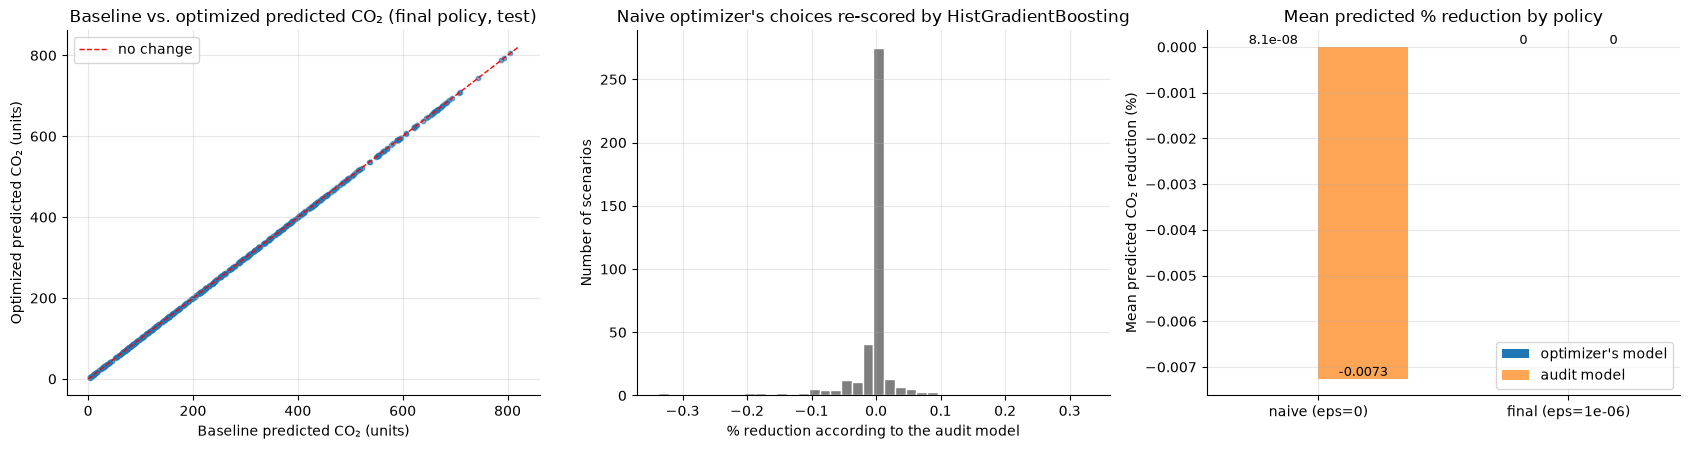

In [74]:
# "Optimizer's curse" check: a naive optimizer (eps = 0) always picks the candidate the model likes best,
# so even pure model noise looks like a saving. Re-scoring its choices with a different model exposes this.
res_naive = select_policy(scored_test, SLACK_MAIN, 0.0)
res_naive["audit_pct_reduction"] = audit_pct_reduction(scored_test, res_naive, audit_model)
curse = pd.DataFrame({
    "naive optimizer (eps = 0)": [100 * res_naive["switched"].mean(), res_naive["pct_reduction"].mean(),
                                  res_naive["pct_reduction"].max(), res_naive["audit_pct_reduction"].mean()],
    f"final policy (eps = {EPS_STAR})": [100 * res_test["switched"].mean(), feas["pct_reduction"].mean(),
                                         feas["pct_reduction"].max(), feas["audit_pct_reduction"].mean()]},
    index=["% of scenarios changed", "mean predicted % reduction", "max predicted % reduction",
           "mean % reduction re-scored by audit model"])
display(curse.apply(lambda col: col.map(lambda v: f"{v:.3g}")))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
lim = [0, max(feas["base_co2"].max(), feas["opt_co2"].max()) * 1.02]
ax[0].scatter(feas["base_co2"], feas["opt_co2"], s=10, alpha=0.6)
ax[0].plot(lim, lim, "r--", lw=1, label="no change")
ax[0].set(title="Baseline vs. optimized predicted CO2 (final policy, test)", xlabel="Baseline predicted CO2 (units)", ylabel="Optimized predicted CO2 (units)"); ax[0].legend()
ax[1].hist(res_naive["audit_pct_reduction"].dropna(), bins=40, color="tab:gray", edgecolor="white")
ax[1].set(title=f"Naive optimizer's choices re-scored by {audit_name}", xlabel="% reduction according to the audit model", ylabel="Number of scenarios")
labels = ["naive (eps=0)", f"final (eps={EPS_STAR})"]
vals_opt = [res_naive["pct_reduction"].mean(), feas["pct_reduction"].mean()]
vals_aud = [res_naive["audit_pct_reduction"].mean(), feas["audit_pct_reduction"].mean()]
xx, w = np.arange(2), 0.36
bars1 = ax[2].bar(xx - w / 2, vals_opt, w, label="optimizer's model")
bars2 = ax[2].bar(xx + w / 2, vals_aud, w, label="audit model", alpha=0.7)
for bars in (bars1, bars2):
    for bar in bars:
        ax[2].annotate(f"{bar.get_height():.2g}", (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                       ha="center", va="bottom", fontsize=9)
ax[2].set_xticks(xx); ax[2].set_xticklabels(labels)
ax[2].set(title="Mean predicted % reduction by policy", ylabel="Mean predicted CO2 reduction (%)"); ax[2].legend()
plt.tight_layout(); plt.show()

Predicted CO2 saving of a lower-traffic alternative with NO extra distance (test scenarios):


,mean,50%,min,max
delta,,,,
0.1,1.605,1.670,0.006,1.946
0.2,3.012,3.279,0.006,3.826
0.3,4.249,4.866,0.006,5.615



Break-even extra distance (%) at slack = 10%:


,share with a positive break-even (%),median break-even detour (%),mean break-even detour (%),share reaching the 30% grid limit (%)
delta,,,,
0.1,95.75,1.5,1.40,0.0
0.2,95.75,3.0,2.81,0.0
0.3,95.75,5.0,4.14,0.0


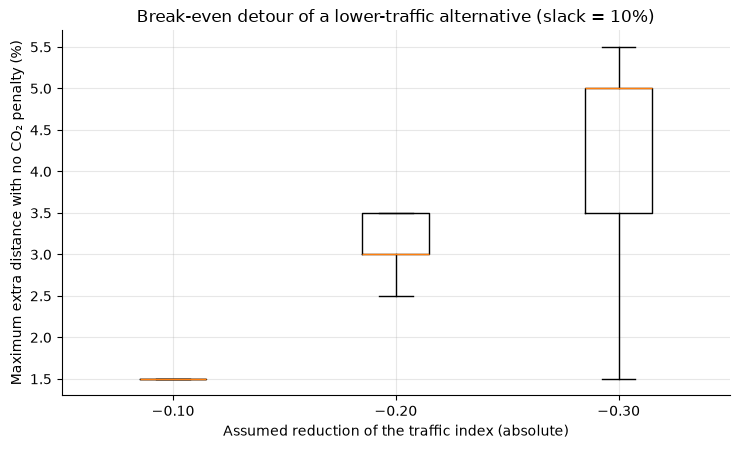

In [75]:
# Problem B results: break-even detour of hypothetical lower-traffic alternatives
zero = routes_test[routes_test["detour"] == 0].copy()
zero["pct_saving_zero_detour"] = 100 * (zero["base_co2"] - zero["co2_new"]) / zero["base_co2"]
print("Predicted CO2 saving of a lower-traffic alternative with NO extra distance (test scenarios):")
display(zero.groupby("delta")["pct_saving_zero_detour"].describe()[["mean", "50%", "min", "max"]].round(3))

be_pct = 100 * be_main
print(f"\nBreak-even extra distance (%) at slack = {SLACK_MAIN:.0%}:")
display(pd.DataFrame({"share with a positive break-even (%)": 100 * (be_pct > 0).mean(),
                      "median break-even detour (%)": be_pct.median(),
                      "mean break-even detour (%)": be_pct.mean(),
                      "share reaching the 30% grid limit (%)": 100 * (be_pct >= 30).mean()}).round(2))

fig, ax = plt.subplots(figsize=(7.5, 4.6))
ax.boxplot([be_pct[d].dropna() for d in DELTAS], showfliers=False)
ax.set_xticks(range(1, len(DELTAS) + 1)); ax.set_xticklabels([f"−{d:.2f}" for d in DELTAS])
ax.set(title=f"Break-even detour of a lower-traffic alternative (slack = {SLACK_MAIN:.0%})",
       xlabel="Assumed reduction of the traffic index (absolute)", ylabel="Maximum extra distance with no CO2 penalty (%)")
plt.tight_layout(); plt.show()

**Interpretation.**

* **Problem A (data-supported levers).** Every scenario has a feasible solution (the recorded configuration itself meets the 10 % limit). Read the tables above: with the validation-calibrated tolerance the optimizer proposes (almost) no change, and the predicted reductions are zero up to numerical precision. The naive version (ε = 0) does "change" many decisions, but its predicted gains are at the level of floating-point noise, and re-scoring its choices with a different model (middle panel) shows only small differences that are not a consistent saving. This is what Section 7 predicted: in this dataset **vehicle code, road code, departure hour and speed carry no information about emissions**, so an ML-driven optimizer correctly finds nothing worth changing. The recorded emissions are shown only for reference; they cannot validate a counterfactual.
* **Problem B (scenario).** Unlike Problem A, the model does predict a clear emission benefit when the traffic index is lowered, and the break-even table translates this into a usable rule: a lower-traffic alternative is worth taking if its extra distance stays below the reported break-even percentage (resolved on a 0.5-percentage-point grid; a break-even of 0 means less than one grid step, which happens when the original traffic is already almost zero). This is a *conditional, scenario-based* result: it needs real route alternatives (with their traffic, distance and elevation) that the dataset does not contain, and the assumption that elevation does not change with the detour.

In both cases the numbers are model predictions, not measured savings.

## 10. Sensitivity analysis

We vary the delivery-time constraint (slack $s$ from −20 % : the delivery must be *faster* than recorded : to +50 %), and examine how results depend on cargo weight and distance. The CO2 predictions of each candidate do not depend on $s$, so each sweep reuses them and only changes feasibility.

Problem A - sensitivity to the delivery-time constraint:


,% feasible,% where recorded config meets limit,mean % reduction,mean opt. travel time,mean base travel time
slack,,,,,
-0.20,71.00,0.0,0.0,1224.150,1650.796
-0.10,85.75,0.0,0.0,1280.225,1539.945
0.00,100.00,100.0,0.0,1444.436,1444.436
0.10,100.00,100.0,0.0,1444.436,1444.436
0.25,100.00,100.0,0.0,1444.436,1444.436
0.50,100.00,100.0,0.0,1444.436,1444.436



Problem B - median break-even detour (%) by traffic reduction (columns) and slack (rows):


delta,0.1,0.2,0.3
slack,,,
-0.20,NaN,NaN,1.5
-0.10,NaN,2.5,5.0
0.00,1.5,3.0,5.0
0.10,1.5,3.0,5.0
0.25,1.5,3.0,5.0
0.50,1.5,3.0,5.0


delta,0.1,0.2,0.3
slack,,,
-0.20,0.0,0.0,21.2
-0.10,0.0,79.5,86.2
0.00,95.8,95.8,95.8
0.10,95.8,95.8,95.8
0.25,95.8,95.8,95.8
0.50,95.8,95.8,95.8


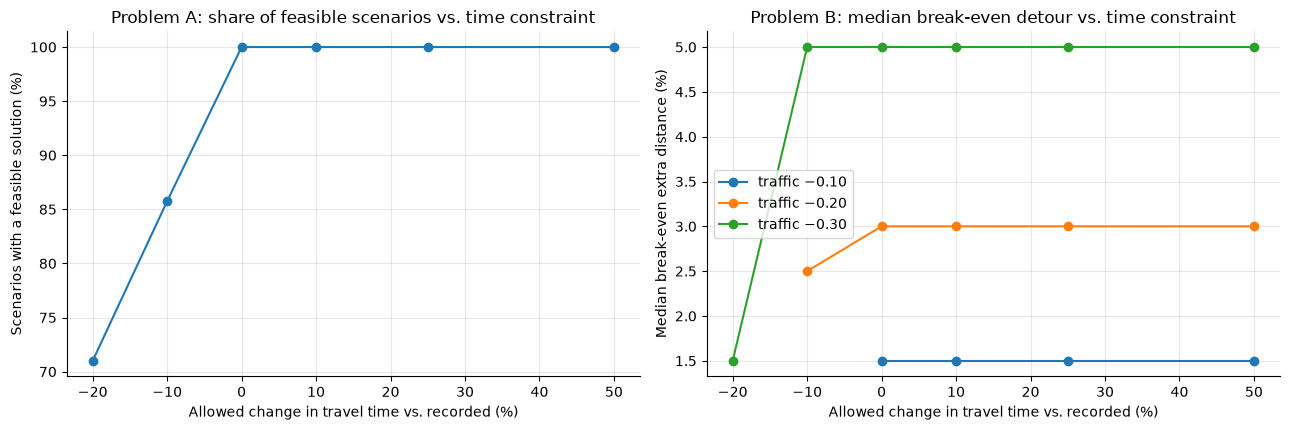

In [80]:
SLACKS = [-0.20, -0.10, 0.0, 0.10, 0.25, 0.50]

# Problem A: effect of the time constraint
rows = []
for s in SLACKS:
    r_ = select_policy(scored_test, s, EPS_STAR); f_ = r_[r_["feasible"]]
    rows.append({"slack": s, "% feasible": 100 * r_["feasible"].mean(),
                 "% where recorded config meets limit": 100 * r_["baseline_meets_limit"].astype(float).mean(),
                 "mean % reduction": f_["pct_reduction"].mean(), "mean opt. travel time": f_["opt_time"].mean(),
                 "mean base travel time": f_["base_time"].mean()})
sens_a = pd.DataFrame(rows).set_index("slack")
print("Problem A - sensitivity to the delivery-time constraint:")
display(sens_a.round(3))

# Problem B: break-even detour vs. slack
rows = []
for s in SLACKS:
    b_ = 100 * break_even(routes_test, s)
    for d in DELTAS:
        rows.append({"slack": s, "delta": d, "median_break_even_%": b_[d].median(), "share_positive_%": 100 * (b_[d] > 0).mean()})
sens_b = pd.DataFrame(rows)
print("\nProblem B - median break-even detour (%) by traffic reduction (columns) and slack (rows):")
display(sens_b.pivot(index="slack", columns="delta", values="median_break_even_%").round(2))
display(sens_b.pivot(index="slack", columns="delta", values="share_positive_%").round(1))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
ax[0].plot(100 * sens_a.index, sens_a["% feasible"], marker="o")
ax[0].set(title="Problem A: share of feasible scenarios vs. time constraint", xlabel="Allowed change in travel time vs. recorded (%)", ylabel="Scenarios with a feasible solution (%)")
for d in DELTAS:
    sub = sens_b[sens_b["delta"] == d]
    ax[1].plot(100 * sub["slack"], sub["median_break_even_%"], marker="o", label=f"traffic −{d:.2f}")
ax[1].set(title="Problem B: median break-even detour vs. time constraint", xlabel="Allowed change in travel time vs. recorded (%)", ylabel="Median break-even extra distance (%)")
ax[1].legend()
plt.tight_layout(); plt.show()

In [82]:
# Dependence on cargo weight and distance (terciles of the test scenarios)
tab = res_test[res_test["feasible"]].copy()
tab["cargo_tercile"] = pd.qcut(tab["cargo_weight"], 3, labels=["light", "medium", "heavy"])
tab["distance_tercile"] = pd.qcut(tab["distance_km"], 3, labels=["short", "medium", "long"])
be20 = (100 * break_even(routes_test, SLACK_MAIN)[0.20]).rename("break_even_pct_delta020")
tab = tab.join(be20)
print("Problem A (mean predicted % reduction) and Problem B (median break-even detour, traffic −0.20) by group:")
for key in ["cargo_tercile", "distance_tercile"]:
    display(tab.groupby(key, observed=True).agg(n=("pct_reduction", "size"), A_mean_pct_reduction=("pct_reduction", "mean"),
                                                 A_mean_baseline_co2=("base_co2", "mean"),
                                                 B_median_break_even_pct=("break_even_pct_delta020", "median")).round(3))

Problem A (mean predicted % reduction) and Problem B (median break-even detour, traffic −0.20) by group:


,n,A_mean_pct_reduction,A_mean_baseline_co2,B_median_break_even_pct
cargo_tercile,,,,
light,134,0.0,205.993,3.0
medium,133,0.0,325.929,3.0
heavy,133,0.0,357.690,3.0


,n,A_mean_pct_reduction,A_mean_baseline_co2,B_median_break_even_pct
distance_tercile,,,,
short,134,0.0,96.248,3.0
medium,133,0.0,286.502,3.0
long,133,0.0,507.687,3.0


**Interpretation.**

* **Emissions vs. delivery-time trade-off (Problem A).** Tightening the time limit removes feasible solutions (deliveries whose recorded speed is already near the observed ceiling of the grid cannot be made faster enough) but leaves the achievable emissions unchanged, and relaxing it changes nothing either. Through vehicle, road, hour and speed there is therefore **no emissions-time trade-off in this data**; real vehicles would typically show one (fuel use rising with speed), which the data cannot reveal.
* **Problem B.** The time constraint only binds when it is *tighter than the recorded travel time* (negative slack): an alternative is then admissible only if its lower traffic already shortens the trip enough, so the share of admissible alternatives drops sharply for small traffic reductions. Once the limit is at or above the recorded time, the emissions criterion is the limiting factor and the break-even detour no longer changes with the slack (flat curves).
* **Cargo and distance.** The group tables show that the break-even detour is practically the same for light, medium and heavy cargo and for short, medium and long trips: in the model, emissions scale with distance and with a cargo-dependent factor, so a *relative* change in traffic or distance affects them by the same percentage; what changes is the *absolute* amount of CO2 saved by a given percentage (compare the baseline emissions column).

## 11. Conclusion and limitations

The cell below pulls the key numbers from the objects computed above so that the text is consistent with the execution.

In [86]:
b = results.loc[best_name]
usable = [c for c in corr_table.index if c in PRE_FEATURES]          # pre-dispatch columns only
top3 = corr_table.loc[usable, "pearson"].abs().sort_values(ascending=False).index[:3]
top3_txt = ", ".join("%s (r=%.2f)" % (c, corr_table.loc[c, "pearson"]) for c in top3)
veh_gap = train.groupby("vehicle_type")[TARGET].mean().agg(lambda x: x.max() - x.min())
road_gap = train.groupby("road_type")[TARGET].mean().agg(lambda x: x.max() - x.min())
time_err = ((df["travel_time"] - df["time_identity"]).abs() / df["travel_time"]).max()
zero_savings = ", ".join("%.2f%%" % zero.loc[zero["delta"] == d, "pct_saving_zero_detour"].mean() for d in DELTAS)
be_medians = ", ".join("%.1f%%" % be_pct[d].median() for d in DELTAS)

print("MAIN EDA FINDINGS")
print("  - Strongest pre-dispatch associations with CO2: " + top3_txt)
print("  - Vehicle / road codes: group means of CO2 differ by at most %.2f / %.2f units" % (veh_gap, road_gap))
print("  - travel_time reproduces distance/speed*60*(1+traffic) to %.1e relative error" % time_err)
print("  - distance_km vs great-circle distance from the coordinates: r = %.3f (data very likely synthetic)" % df["gc_distance_km"].corr(df["distance_km"]))
print("  - CO2 is reproduced by distance x interactions with max |error| = %.1e (test split)" % err.max())
print("\nBEST REGRESSION MODEL (pre-dispatch features)")
print("  - %s: validation RMSE = %.3g; TEST MAE = %.3g, RMSE = %.3g, R2 = %.6f" % (best_name, b["val_RMSE"], b["test_MAE"], b["test_RMSE"], b["test_R2"]))
print("  - Dummy baseline TEST RMSE = %.1f;  best tree model (%s) TEST RMSE = %.2f" % (
    results.loc["Dummy (train mean)", "test_RMSE"], audit_name, results.loc[audit_name, "test_RMSE"]))
print("\nOPTIMIZATION A (vehicle, road, hour, speed; time limit +%d%%)" % (SLACK_MAIN * 100))
print("  - Method: constrained enumeration of %d candidates per delivery, objective = predicted CO2 of %s, tolerance eps = %g" % (
    len(candidate_grid), best_name, EPS_STAR))
print("  - %d/%d test scenarios feasible; decision changed in %d" % (res_test["feasible"].sum(), len(res_test), res_test["switched"].sum()))
print("  - Predicted CO2: baseline %.2f -> optimized %.2f (mean reduction %.3g%%, max %.3g%%); audit model: %.3g%%" % (
    feas["base_co2"].mean(), feas["opt_co2"].mean(), feas["pct_reduction"].mean(), feas["pct_reduction"].max(), feas["audit_pct_reduction"].mean()))
print("  - Naive optimizer (eps = 0): changes %.0f%% of decisions, mean audit-model reduction %.3g%%" % (
    100 * res_naive["switched"].mean(), res_naive["audit_pct_reduction"].mean()))
print("  - Lever validation: R2 of the levers on the residual of a lever-free model = %.5f" % r2_levers)
print("\nOPTIMIZATION B (scenario: lower-traffic route alternative)")
print("  - Zero-detour predicted saving for traffic -0.10 / -0.20 / -0.30: " + zero_savings)
print("  - Median break-even extra distance at slack %d%%: %s" % (SLACK_MAIN * 100, be_medians))

MAIN EDA FINDINGS
  - Strongest pre-dispatch associations with CO2: distance_km (r=0.90), cargo_weight (r=0.37), traffic_index (r=0.07)
  - Vehicle / road codes: group means of CO2 differ by at most 1.34 / 1.02 units
  - travel_time reproduces distance/speed*60*(1+traffic) to 7.3e-16 relative error
  - distance_km vs great-circle distance from the coordinates: r = -0.004 (data very likely synthetic)
  - CO2 is reproduced by distance x interactions with max |error| = 6.0e-11 (test split)

BEST REGRESSION MODEL (pre-dispatch features)
  - Ridge + interactions: validation RMSE = 4.2e-06; TEST MAE = 2.92e-06, RMSE = 4.26e-06, R2 = 1.000000
  - Dummy baseline TEST RMSE = 201.1;  best tree model (HistGradientBoosting) TEST RMSE = 3.22

OPTIMIZATION A (vehicle, road, hour, speed; time limit +10%)
  - Method: constrained enumeration of 1728 candidates per delivery, objective = predicted CO2 of Ridge + interactions, tolerance eps = 1e-06
  - 400/400 test scenarios feasible; decision changed in 

### Can a machine-learning model support lower-emission delivery decisions while maintaining delivery-time and cargo constraints?

* **Prediction:** yes : a pre-dispatch model predicts emissions with small error on held-out data.
* **Optimization with the data-supported levers (vehicle code, road code, departure hour, planned speed): no savings can be demonstrated.** The data show that these variables carry no information about emissions beyond distance, cargo, traffic and elevation, so the ML-driven optimizer correctly finds nothing worth changing; a naive optimizer (ε = 0) would still change almost every decision, but only by chasing differences far below the models' resolution, which a second model does not confirm. This is an honest negative result about *this dataset*, not evidence about real fleets.
* **Scenario-based decision rule:** the model does show that emissions respond to traffic exposure and distance. The break-even detour of a hypothetical lower-traffic alternative is a concrete, ML-derived rule for choosing between routes *if* a dispatcher has such alternatives, subject to the time limit.

### Limitations and future work

* **Synthetic-data risk.** Features are nearly independent and uniformly distributed, the emission target is a near-deterministic function of four variables, `distance_km` is inconsistent with the coordinates, and vehicle/road/hour/speed have no effect. Real operations differ on all of these points.
* **Unknown semantics.** The meaning of the vehicle and road codes, and the units of emissions, cargo and travel time, are not documented; no physical relationship was assumed.
* **Missing operational constraints.** No vehicle capacity, cost, driver hours, time windows, fleet availability or alternative routes are available; the time constraint relies on the identity found in the file and on a tolerance $s$ chosen by assumption.
* **No road-network paths.** Route alternatives in Problem B are hypothetical (traffic reduced by $\delta$, distance increased by $x$, elevation unchanged).
* **Predicted vs. verified savings.** Every reduction reported here is a model prediction. A single historical record does not reveal what would have happened under another decision; verification would need controlled trials or a simulator calibrated on real telemetry.
* **Future improvements.** Use real telematics data with vehicle specifications, add multi-delivery routing (VRP) with capacity and time windows so that load consolidation and routing can be optimized, include fuel-based emission factors, quantify uncertainty (e.g. quantile regression or conformal intervals) before acting on small predicted differences, and validate the policy in a pilot.